# Cross-sample pattern comparison benchmark

Here we visualize benchmark results for the Comparator implementations using spatial datasets with ground truth biology:

1. AD/PIG: Plaque-induced gene (PIG) module from a spatial dataset of Alzheimer's disease mouse model.
2. brain_dev: Brain development module from a spatial dataset of developing mouse brain.

## Loading source data and precomputed workflow results

In [1]:
import sys
import json
from pathlib import Path

_THIS_DIR = Path.cwd()
for cand in (_THIS_DIR, _THIS_DIR.parent, _THIS_DIR.parent.parent):
    if (cand / "scripts" / "comparator_benchmark" / "config.py").exists():
        if str(cand) not in sys.path:
            sys.path.insert(0, str(cand))
        __package__ = "scripts.comparator_benchmark"
        break

import math
import textwrap
import warnings

import matplotlib as mpl
import matplotlib.collections as mcollections
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import matplotlib.patheffects as path_effects
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from quadsv.statistics import apply_bh_correction

from .config import (
    AD_ENRICH_CONTRAST_FILE,
    AD_PIG_ENRICHMENT_TOP_N,
    AD_PIG_ANISOTROPY_FILE,
    AD_PIG_FULL_NULL_ECDF_FILE,
    AD_PIG_FULL_TESTS_FILE,
    AD_PIG_POS_CONTROLS,
    AD_PIG_RADIAL_BIN_ROBUSTNESS_FILE,
    AD_PIG_SPECTRAL_REPLICATE_DISTANCE_FILE,
    AD_PIG_REFERENCE_BINNING,
    AD_PIG_REFERENCE_FEATURE_MODE,
    AD_PIG_REFERENCE_INPUT,
    AD_PIG_REFERENCE_N_RADIAL_BINS,
    FIGURE_DIR,
    PROJECT_ROOT,
    RESULT_DIR,
)
from .utils import (
    add_length_scale_axis,
    fit_all_samples,
    format_pvalue,
    geometric_frequency_edges as _geometric_frequency_edges,
    l1_normalize_rows,
    load_panel,
    radial_frequency_axis,
    select_gene_panel,
)
from .plot_ad_pig_gene_profiles import generate_pdf as generate_ad_pig_gene_profile_pdf

warnings.filterwarnings("ignore", category=UserWarning, message=".*This figure includes Axes.*")

mpl.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "font.family": ["Arial", "DejaVu Sans"],
    "font.size": 6,
    "axes.titlesize": 7,
    "axes.labelsize": 6,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 5.5,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "figure.constrained_layout.use": False,
})

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = RESULT_DIR / "enrichment_cache"

FULL_TESTS = pd.read_csv(RESULT_DIR / AD_PIG_FULL_TESTS_FILE)
NULL_ECDF = pd.read_csv(RESULT_DIR / AD_PIG_FULL_NULL_ECDF_FILE)
for _df in (FULL_TESTS, NULL_ECDF):
    if "requested_n_radial_bins" not in _df.columns:
        _df["requested_n_radial_bins"] = _df["n_radial_bins"]


def _scenario_wide(input_transform, binning, feature_mode):
    sub = FULL_TESTS[
        FULL_TESTS["panel"].eq("ad_pig")
        & FULL_TESTS["input"].eq(input_transform)
        & FULL_TESTS["binning"].eq(binning)
        & FULL_TESTS["feature_mode"].eq(feature_mode)
        & FULL_TESTS["requested_n_radial_bins"].eq(AD_PIG_REFERENCE_N_RADIAL_BINS)
    ].copy()
    if sub.empty:
        return pd.DataFrame(columns=["panel", "Feature", "P_DE", "P_DF", "P_DF_norm"])
    wide = sub.pivot_table(index="Feature", columns="test", values="P_value", aggfunc="first")
    wide = wide.rename(columns={test: f"P_{test}" for test in wide.columns}).reset_index()
    wide.insert(0, "panel", "ad_pig")
    return wide

# Load the real test results for the reference scenario
REAL = _scenario_wide(
    AD_PIG_REFERENCE_INPUT,
    AD_PIG_REFERENCE_BINNING,
    AD_PIG_REFERENCE_FEATURE_MODE,
)
if REAL.empty:
    raise RuntimeError("Reference AD/PIG scenario is missing from ad_pig_full_tests.csv")

TESTS = ["DE", "DF", "DF_norm"]
TEST_DISPLAY = {"DE": "DE", "DF": "DF", "DF_norm": "DF-norm"}
TEST_COLORS = {"DE": "#7f7f7f", "DF": "#1f77b4", "DF_norm": "#d62728"}


# Null ECDF caches are already in long form.  Figure code subsets these
# directly by scenario rather than materializing extra compatibility tables.

NULL_CALIB_ALL = NULL_ECDF.rename(columns={"input": "normalization"}).copy()
linear_mask = NULL_CALIB_ALL["binning"].eq("linear")
log_radial_mask = NULL_CALIB_ALL["binning"].eq("log") & NULL_CALIB_ALL["feature_mode"].eq("radial")
NULL_CALIB = NULL_CALIB_ALL[linear_mask].copy()
GEOM_NULL_CALIB = NULL_CALIB_ALL[log_radial_mask].copy()
GEOM_NULL_CALIB["feature_mode"] = "geometric"

RADIAL_BIN_DIAG = pd.read_csv(RESULT_DIR / AD_PIG_RADIAL_BIN_ROBUSTNESS_FILE).rename(
    columns={"input": "normalization"}
)
if "requested_n_radial_bins" not in RADIAL_BIN_DIAG.columns:
    RADIAL_BIN_DIAG["requested_n_radial_bins"] = RADIAL_BIN_DIAG["n_radial_bins"]
RADIAL_BIN_DIAG["residual_effective_rank_fraction"] = (
    RADIAL_BIN_DIAG["residual_effective_rank"] / RADIAL_BIN_DIAG["n_frequency_bins"].clip(lower=1)
)
RADIAL_BIN_DIAG["binning"] = RADIAL_BIN_DIAG["binning"].replace({"log": "geometric"})
AD_PIG_ANISOTROPY = pd.read_csv(RESULT_DIR / AD_PIG_ANISOTROPY_FILE)
AD_PIG_REPLICATE_DISTANCE = pd.read_csv(RESULT_DIR / AD_PIG_SPECTRAL_REPLICATE_DISTANCE_FILE)
AD_PIG_ANISOTROPY_SAMPLE_SUMMARY = (
    AD_PIG_ANISOTROPY.groupby(["panel", "sample", "group", "gene_set"], sort=False)["anisotropy"]
    .agg(
        n_genes="count",
        mean="mean",
        median="median",
        q25=lambda x: float(np.nanpercentile(x, 25)),
        q75=lambda x: float(np.nanpercentile(x, 75)),
        min="min",
        max="max",
    )
    .reset_index()
)
AD_PIG_ANISOTROPY_SAMPLE_SUMMARY["iqr"] = (
    AD_PIG_ANISOTROPY_SAMPLE_SUMMARY["q75"] - AD_PIG_ANISOTROPY_SAMPLE_SUMMARY["q25"]
)
AD_PIG_ANISOTROPY_PIG = AD_PIG_ANISOTROPY[AD_PIG_ANISOTROPY["gene_set"] == "PIG"].copy()
AD_PIG_ANISOTROPY_SAMPLE_SUMMARY_PIG = AD_PIG_ANISOTROPY_SAMPLE_SUMMARY[
    AD_PIG_ANISOTROPY_SAMPLE_SUMMARY["gene_set"] == "PIG"
].copy()

GROUP_COLORS = {"WT": "#4d4d4d", "AD": "#e69f00"}
RADIAL_LABEL = "radial"
RADIAL_SHORT = "r"
GENE_STORIES = {
    "ad_pig": [
        ("Apoe", "broad DAM/lipid activation"),
        ("Tyrobp", "plaque microglial spatial remodeling"),
    ],
}

print("project root:", PROJECT_ROOT)
print("cached full observed tests:", FULL_TESTS.shape)
print("cached null ECDF p-values:", NULL_ECDF.shape)
print("derived reference tests:", REAL.shape)
print("derived null calibration:", NULL_CALIB_ALL.shape)
print("cached radial-bin robustness:", RADIAL_BIN_DIAG.shape)
print("cached AD/PIG anisotropy:", AD_PIG_ANISOTROPY.shape)
print("cached AD/PIG spectral replicate distances:", AD_PIG_REPLICATE_DISTANCE.shape)
print("derived AD/PIG anisotropy sample summary:", AD_PIG_ANISOTROPY_SAMPLE_SUMMARY.shape)

print("\nAD/PIG PIG-gene anisotropy, sample medians:")
print(
    AD_PIG_ANISOTROPY_SAMPLE_SUMMARY_PIG
    .sort_values(["group", "sample"])[["group", "sample", "median", "iqr"]]
    .to_string(index=False, float_format=lambda x: f"{x:.4f}")
)
anis_group_summary = AD_PIG_ANISOTROPY_PIG.groupby("group")["anisotropy"].agg(
    n="count",
    median="median",
    q25=lambda x: np.nanpercentile(x, 25),
    q75=lambda x: np.nanpercentile(x, 75),
)
anis_group_summary["iqr"] = anis_group_summary["q75"] - anis_group_summary["q25"]
print("\nAD/PIG PIG-gene anisotropy, group summary:")
print(anis_group_summary[["n", "median", "iqr"]].to_string(float_format=lambda x: f"{x:.4f}"))
anis_gene_mean = AD_PIG_ANISOTROPY_PIG.pivot_table(
    index="gene", columns="group", values="anisotropy", aggfunc="mean"
)
if {"WT", "AppNL-G-F"}.issubset(anis_gene_mean.columns):
    anis_gene_mean["delta_AppNL-G-F_minus_WT"] = anis_gene_mean["AppNL-G-F"] - anis_gene_mean["WT"]
    print("\nTop PIG genes by AppNL-G-F minus WT mean anisotropy:")
    print(
        anis_gene_mean.sort_values("delta_AppNL-G-F_minus_WT", ascending=False)
        .head(8)[["AppNL-G-F", "WT", "delta_AppNL-G-F_minus_WT"]]
        .to_string(float_format=lambda x: f"{x:.4f}")
    )

project root: /Users/jysumac/Projects/quadsv-paper
cached full observed tests: (72480, 12)
cached null ECDF p-values: (579840, 10)
derived reference tests: (3020, 5)
derived null calibration: (579840, 10)
cached radial-bin robustness: (24, 22)
cached AD/PIG anisotropy: (24160, 10)
cached AD/PIG spectral replicate distances: (1123440, 14)
derived AD/PIG anisotropy sample summary: (16, 12)

AD/PIG PIG-gene anisotropy, sample medians:
    group sample  median    iqr
AppNL-G-F N04_D1  0.0488 0.0139
AppNL-G-F N04_E1  0.0480 0.0111
AppNL-G-F N05_C2  0.0388 0.0116
AppNL-G-F N05_D2  0.0461 0.0138
       WT B04_D1  0.0340 0.0108
       WT B04_E1  0.0340 0.0108
       WT B05_D2  0.0345 0.0118
       WT B05_E2  0.0301 0.0060

AD/PIG PIG-gene anisotropy, group summary:
             n  median    iqr
group                        
AppNL-G-F  212  0.0460 0.0149
WT         212  0.0328 0.0104

Top PIG genes by AppNL-G-F minus WT mean anisotropy:
group  AppNL-G-F     WT  delta_AppNL-G-F_minus_WT
gene    

In [2]:
# Load the reference AD/PIG samples once; figure panels reuse this fitted comparator.
ad_samples, _ad_meta, ad_sets = load_panel("ad_pig")
ad_base_genes = select_gene_panel(ad_samples)
ad_present_genes = set.intersection(*(set(a.var_names) for a in ad_samples.values()))
ad_pig_present = [g for g in AD_PIG_POS_CONTROLS if g in ad_present_genes]
ad_genes = list(dict.fromkeys(ad_base_genes + ad_pig_present))
ad_real = next(s for s in ad_sets if s.null_type == "real")

# Compute radial-binned per-(gene, sample) spectra
ad_cmp, ad_paths = fit_all_samples(ad_samples, ad_genes, "radial")

for panel, genes in GENE_STORIES.items():
    tested = set(ad_genes)
    missing = [g for g, _ in genes if g not in tested]
    if missing:
        raise KeyError(f"Configured genes missing from {panel}: {missing}")

print(f"ad_pig: {len(ad_samples)} samples, {len(ad_genes)} genes, spectra={ad_cmp.spectra_.shape}")

ad_pig: 8 samples, 3020 genes, spectra=(8, 3020, 30)


## AD/PIG analysis figures

### Shared helpers for all figures

In [3]:
_pformat = format_pvalue

def _neglog10(x):
    """Return clipped -log10 values for stable p-value plotting."""
    return -np.log10(np.clip(np.asarray(x, dtype=float), 1e-300, 1.0))

def _panel_real(panel):
    """Return reference-scenario test results for one panel."""
    return REAL[REAL["panel"] == panel].copy()

def _gene_stats(panel, gene):
    """Return DE, DF, and DF-norm p-values for one gene."""
    row = _panel_real(panel).set_index("Feature").loc[gene]
    return {"DE": row["P_DE"], "DF": row["P_DF"], "DF_norm": row["P_DF_norm"]}

def _fdr_counts(panel, alpha=0.05):
    """Count BH-FDR significant genes for each test."""
    df = _panel_real(panel)
    return {
        "DE": int((apply_bh_correction(df["P_DE"].to_numpy()) < alpha).sum()),
        "DF": int((apply_bh_correction(df["P_DF"].to_numpy()) < alpha).sum()),
        "DF_norm": int((apply_bh_correction(df["P_DF_norm"].to_numpy()) < alpha).sum()),
    }

def _binary_indices(sample_set, paths):
    """Map sample-set paths to comparator sample indices."""
    path_to_idx = {p: i for i, p in enumerate(paths)}
    a_idx = [path_to_idx[p] for p in sample_set.a_paths if p in path_to_idx]
    b_idx = [path_to_idx[p] for p in sample_set.b_paths if p in path_to_idx]
    return np.asarray(a_idx, dtype=int), np.asarray(b_idx, dtype=int)


ad_wt_idx, ad_tg_idx = _binary_indices(ad_real, ad_paths)

def _gene_values(adata, gene):
    """Return log1p expression for one gene from one AnnData object."""
    x = adata[:, gene].X
    if sparse.issparse(x):
        x = x.toarray()
    return np.log1p(np.asarray(x).ravel())

def _gene_vmax(samples, gene, q=0.99):
    """Compute a shared upper color limit across sample maps."""
    vals = np.concatenate([_gene_values(a, gene) for a in samples])
    vmax = float(np.quantile(vals[np.isfinite(vals)], q))
    return max(vmax, 1e-6)

def _spatial_grid_step(values):
    """Estimate the regular spot spacing used for tile rendering."""
    uniq = np.sort(np.unique(np.round(np.asarray(values, dtype=float), 6)))
    diffs = np.diff(uniq)
    diffs = diffs[diffs > 1e-6]
    if len(diffs) == 0:
        return 1.0
    return float(np.median(diffs))

def _plot_spatial(ax, adata, gene, title=None, vmin=0.0, vmax=None):
    """Draw a gap-free spatial expression heatmap from spot coordinates."""
    coords = np.asarray(adata.obsm["spatial"], dtype=float)
    vals = _gene_values(adata, gene)
    dx = _spatial_grid_step(coords[:, 0])
    dy = _spatial_grid_step(coords[:, 1])
    tiles = [
        mpatches.Rectangle((x - dx / 2, y - dy / 2), dx * 1.015, dy * 1.015)
        for x, y in coords
    ]
    sc = mcollections.PatchCollection(
        tiles,
        cmap="magma",
        norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax),
        linewidths=0,
        edgecolors="none",
        antialiased=False,
    )
    sc.set_array(vals)
    ax.add_collection(sc)
    ax.set_xlim(coords[:, 0].min() - dx / 2, coords[:, 0].max() + dx / 2)
    ax.set_ylim(coords[:, 1].min() - dy / 2, coords[:, 1].max() + dy / 2)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=5.5, pad=1)
    for spine in ax.spines.values():
        spine.set_visible(False)
    return sc

def _representative_ad_paths():
    """Return representative WT and AppNL-G-F sample paths."""
    return ad_real.a_paths[0], ad_real.b_paths[0]

def preview_subplot_panel(draw_func, *, figsize=(6.8, 2.1)):
    """Render one notebook-only preview panel from a subplot-spec helper."""
    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(1, 1, figure=fig, left=0.06, right=0.98, top=0.90, bottom=0.12)
    draw_func(gs[0])
    plt.show()
    plt.close(fig)

### The main figure

#### Methodology illustration

In [4]:
def _raw_gene_values(adata, gene):
    x = adata[:, gene].X
    if sparse.issparse(x):
        x = x.toarray()
    return np.asarray(x).ravel().astype(float)

def _rasterize_grid(adata, gene, n_grid=64):
    """Convert the 1D flattened expression array to a 2D grid"""
    coords = np.asarray(adata.obsm["spatial"])
    vals = _raw_gene_values(adata, gene)
    x = coords[:, 0]
    y = coords[:, 1]
    bins_x = np.linspace(x.min(), x.max(), n_grid + 1)
    bins_y = np.linspace(y.min(), y.max(), n_grid + 1)
    sums, _, _ = np.histogram2d(y, x, bins=[bins_y, bins_x], weights=vals)
    counts, _, _ = np.histogram2d(y, x, bins=[bins_y, bins_x])
    grid = np.divide(sums, counts, out=np.zeros_like(sums), where=counts > 0)
    return grid, [x.min(), x.max(), y.min(), y.max()]


def _plot_raw_spatial_thumbnail(ax, adata, gene, label, vmax):
    coords = np.asarray(adata.obsm["spatial"], dtype=float)
    vals = _raw_gene_values(adata, gene)
    dx = _spatial_grid_step(coords[:, 0]) * 1.08
    dy = _spatial_grid_step(coords[:, 1]) * 1.08
    tiles = [
        mpatches.Rectangle((x - dx / 2, y - dy / 2), dx, dy)
        for x, y in coords
    ]
    thumb_cmap = mpl.colors.LinearSegmentedColormap.from_list(
        "raw_count_thumb",
        ["#f3f3f3", "#3b0f70", "#b5367a", "#fb8861", "#fcfdbf"],
    )
    coll = mcollections.PatchCollection(
        tiles,
        array=vals,
        cmap=thumb_cmap,
        norm=mpl.colors.PowerNorm(gamma=0.62, vmin=0, vmax=vmax),
        linewidth=0,
        edgecolor="none",
        antialiased=False,
        rasterized=True,
    )
    ax.add_collection(coll)
    ax.set_xlim(coords[:, 0].min() - dx, coords[:, 0].max() + dx)
    ax.set_ylim(coords[:, 1].min() - dy, coords[:, 1].max() + dy)
    ax.set_aspect("equal")
    ax.set_facecolor("white")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.text(0.05, 0.88, label, transform=ax.transAxes, color="white", fontsize=5,
            path_effects=[path_effects.withStroke(linewidth=1.0, foreground="black")])
    for s in ax.spines.values():
        s.set_visible(False)
    return coll


def _full_power_for_display(power, grid_shape, fft_solver):
    if fft_solver == "fft2":
        return np.asarray(power)
    ny, nx = grid_shape
    half = power.shape[-1]
    full = np.zeros(power.shape[:-1] + (nx,), dtype=power.dtype)
    full[..., :half] = power
    flipped_ky = np.empty_like(power)
    flipped_ky[..., 0, :] = power[..., 0, :]
    if ny > 1:
        flipped_ky[..., 1:, :] = power[..., :0:-1, :]
    last_interior = half - 1 if nx % 2 == 0 else half
    for j in range(1, last_interior):
        full[..., nx - j] = flipped_ky[..., j]
    return full


def _format_frequency_tick(value):
    if abs(value) < 1e-12:
        return "0"
    return f"{value:.3f}"


def _fft_display_data(cmp, sample_idx, gene_idx):
    """Compute the full frequency-domain representation of a gene in a given sample."""
    sample_idx = int(sample_idx)
    raw_2d = getattr(cmp, "_raw_2d_spectra", None)
    if raw_2d is not None:
        power = np.maximum(raw_2d[sample_idx][gene_idx], 1e-12)
        grid_shape = cmp._grid_shapes[sample_idx]
        spacing = cmp._spacings[sample_idx] if cmp._spacings is not None else (1.0, 1.0)
        full = _full_power_for_display(power, grid_shape, cmp._spectrum_fft_solver)
        shown = np.fft.fftshift(full, axes=(-2, -1))
        ny, nx = grid_shape
        dy, dx = spacing
    else:
        gene = cmp.gene_names[gene_idx]
        adata = ad_samples[ad_paths[sample_idx]]
        grid, spatial_extent = _rasterize_grid(adata, gene, n_grid=64)
        work = grid - np.nanmean(grid)
        shown = np.abs(np.fft.fftshift(np.fft.fft2(work))) ** 2
        ny, nx = shown.shape
        dx = (spatial_extent[1] - spatial_extent[0]) / max(nx - 1, 1)
        dy = (spatial_extent[3] - spatial_extent[2]) / max(ny - 1, 1)
    kx = np.fft.fftshift(np.fft.fftfreq(nx, d=dx))
    ky = np.fft.fftshift(np.fft.fftfreq(ny, d=dy))
    extent = [float(kx.min()), float(kx.max()), float(ky.min()), float(ky.max())]
    kx_max = float(np.max(np.abs(kx)))
    ky_max = float(np.max(np.abs(ky)))
    xticks = [-kx_max, 0.0, kx_max]
    yticks = [-ky_max, 0.0, ky_max]
    return shown, extent, xticks, [_format_frequency_tick(v) for v in xticks], yticks, [_format_frequency_tick(v) for v in yticks]


def plot_pipeline_flat(axspec):
    """Draw the six-step frequency-domain method schematic."""
    fig = plt.gcf()
    gs = gridspec.GridSpecFromSubplotSpec(
        1, 6,
        subplot_spec=axspec,
        wspace=0.5,
        width_ratios=[1, 1, 1, 1, 1, 1],
    )
    # Select one gene for the demonstration
    _wt_path, tg_path = _representative_ad_paths()
    gene = "Tyrobp"
    gi = ad_genes.index(gene)
    demo_idx = int(ad_tg_idx[0]) # Use the first AD sample for spectral plotting
    spec2d, extent, xticks, xtick_labels, yticks, ytick_labels = _fft_display_data(ad_cmp, demo_idx, gi)
    x = np.arange(ad_cmp.spectra_.shape[-1])
    spectra = np.maximum(ad_cmp.spectra_[:, gi, :], 1e-12)
    wt = spectra[ad_wt_idx]
    tg = spectra[ad_tg_idx]
    wt_shape = wt / np.maximum(wt.sum(axis=1, keepdims=True), 1e-12)
    tg_shape = tg / np.maximum(tg.sum(axis=1, keepdims=True), 1e-12)
    demo_raw = np.maximum(ad_cmp.spectra_[demo_idx, gi, :], 1e-12)
    demo_background = np.exp(np.mean(np.log(np.maximum(ad_cmp.spectra_[demo_idx], 1e-12)), axis=0))
    demo_bg_norm = demo_raw / np.maximum(demo_background, 1e-12)
    title_y = 1.03
    wt_color = GROUP_COLORS["WT"]
    tg_color = GROUP_COLORS["AD"]
    xlabel = "Radial bin k"

    # First panel: raw expression across samples
    ax = fig.add_subplot(gs[0, 0])
    ax.axis("off")
    ax.set_box_aspect(1)
    ax.set_title("Spatial pattern", fontsize=6.5, pad=2, y=title_y)
    thumb_idx = [
        ad_wt_idx[0],
        ad_wt_idx[min(1, len(ad_wt_idx) - 1)],
        ad_tg_idx[0],
        ad_tg_idx[min(1, len(ad_tg_idx) - 1)],
    ]
    thumb_labels = ["WT-1", "WT-2", "AD-1", "AD-2"]
    thumb_adatas = [ad_samples[ad_paths[int(i)]] for i in thumb_idx]
    finite_vals = np.concatenate([_raw_gene_values(a, gene) for a in thumb_adatas])
    vmax = max(float(np.nanquantile(finite_vals[np.isfinite(finite_vals)], 0.985)), 1e-6)
    positions = [(0.02, 0.54, 0.43, 0.43), (0.52, 0.54, 0.43, 0.43), (0.02, 0.08, 0.43, 0.43), (0.52, 0.08, 0.43, 0.43)]
    for pos, lab, adata_i in zip(positions, thumb_labels, thumb_adatas):
        iax = ax.inset_axes(pos)
        _plot_raw_spatial_thumbnail(iax, adata_i, gene, lab, vmax)
    ax.text(0.50, -0.05, f"Unaligned per-sample expression \nacross {len(ad_wt_idx)}WT + {len(ad_tg_idx)}AD samples",
            transform=ax.transAxes, ha="center", va="top", fontsize=5, linespacing=1)

    # Second panel: full 2D power spectrum
    ax = fig.add_subplot(gs[0, 1])
    ax.imshow(np.log10(spec2d + 1e-12), origin="lower", cmap="magma", aspect="equal",
              interpolation="nearest", extent=extent)
    ax.set_box_aspect(1)
    ax.set_title("Power spectrum (aligned)", fontsize=6.5, pad=2, y=title_y)
    ax.set_xlabel(r"$k_x$ (cycles / um)", labelpad=0)
    ax.set_ylabel(r"$k_y$ (cycles / um)", labelpad=-1)
    ax.set_xticks(xticks, xtick_labels)
    ax.set_yticks(yticks, ytick_labels)
    ax.tick_params(axis="both", labelsize=5.0, length=1.6, pad=1)
    ax.text(0.96, 0.94, "per gene per sample", transform=ax.transAxes,
            ha="right", va="top", color="white", fontsize=5,
            bbox=dict(boxstyle="round,pad=0.16", fc="black", ec="none", alpha=0.45))
    for s in ax.spines.values():
        s.set_visible(False)

    # Third panel: radial binning
    ax = fig.add_subplot(gs[0, 2])
    ax.plot(x, demo_raw, color="0.35", lw=1.05, label="raw")
    ax.plot(x, demo_bg_norm, color="0.08", lw=1.05, ls="--", label="bg-norm")
    ax.set_title("Radial binning", fontsize=6.5, pad=2, y=title_y)
    ax.set_xlabel(xlabel, labelpad=1)
    ax.set_ylabel(r"$P(k)$", labelpad=0)
    ax.set_yscale("log")
    ax.set_box_aspect(1)
    raw_i = min(8, len(x) - 1)
    norm_i = min(10, len(x) - 1)
    ax.text(x[raw_i] + 0.5, demo_raw[raw_i] * 1.35, r"raw $P_s(k)$",
            fontsize=5, color="0.35", ha="left", va="bottom")
    ax.text(x[norm_i] + 0.5, demo_bg_norm[norm_i] * 1.75,
            r"$P_s(k)/b_s(k)$", fontsize=5, color="0.08", ha="left", va="bottom")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

    # Fourth panel: group average (DF)
    ax = fig.add_subplot(gs[0, 3])
    for row in wt:
        ax.plot(x, row, color=wt_color, alpha=0.24, lw=0.50)
    for row in tg:
        ax.plot(x, row, color=tg_color, alpha=0.25, lw=0.50)
    ax.plot(x, wt.mean(axis=0), color=wt_color, lw=1.20, label=f"WT (n={len(wt)})")
    ax.plot(x, tg.mean(axis=0), color=tg_color, lw=1.20, label=f"AD (n={len(tg)})")
    ax.set_title("Group average (DF)", fontsize=6.5, pad=2, y=title_y)
    ax.set_xlabel(xlabel, labelpad=1)
    ax.set_ylabel(r"$P(k)$", labelpad=0)
    ax.set_yscale("log")
    ax.set_box_aspect(1)
    ax.legend(frameon=False, fontsize=5, loc="upper right", handlelength=1.10, borderaxespad=0.1)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

    # Fifth panel: L1-norm (DF-norm)
    ax = fig.add_subplot(gs[0, 4])
    for row in wt_shape:
        ax.plot(x, row, color=wt_color, alpha=0.25, lw=0.50)
    for row in tg_shape:
        ax.plot(x, row, color=tg_color, alpha=0.26, lw=0.50)
    ax.plot(x, wt_shape.mean(axis=0), color=wt_color, lw=1.20, label=f"WT (n={len(wt_shape)})")
    ax.plot(x, tg_shape.mean(axis=0), color=tg_color, lw=1.20, label=f"AD (n={len(tg_shape)})")
    ax.set_title("L1-norm (DF-norm)", fontsize=6.5, pad=2, y=title_y)
    ax.set_xlabel(xlabel, labelpad=1)
    ax.set_ylabel(r"$\tilde P(k)$", labelpad=0)
    ax.set_box_aspect(1)
    ax.legend(frameon=False, fontsize=5, loc="upper right", handlelength=1.10, borderaxespad=0.1)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

    # Sixth panel: legend and annotations
    ax = fig.add_subplot(gs[0, 5])
    ax.set_box_aspect(1)
    ax.axis("off")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_title("Two-sample mean test", fontsize=6.5, pad=2, y=title_y)
    ax.text(0.00, 0.90, r"$z_s(k)=\log P_s(k)$ (DF)", fontsize=5, color=TEST_COLORS["DF"])
    ax.text(0.00, 0.72, r"$\tilde z_s(k)=\log\tilde P_s(k)$ (DF-norm)", fontsize=5, color=TEST_COLORS["DF_norm"])
    ax.text(0.00, 0.54, r"$\Delta(k)=\bar z_{AD}(k)-\bar z_{WT}(k)$", fontsize=5)
    ax.text(0.00, 0.36, r"$T^2=\sum_k w_k\,\Delta(k)^2$", fontsize=5)
    ax.text(0.00, 0.18, r"$T^2_{null}\sim\sum_j\lambda_j\chi^2_{1,j}$", fontsize=5)
    ax.text(0.00, 0.00, r"$\lambda_j$ from cross-bin covariance", fontsize=5)

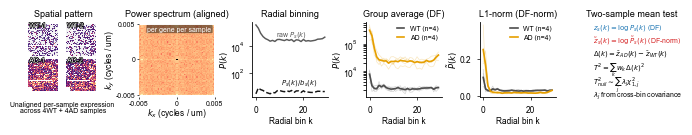

In [5]:
preview_subplot_panel(plot_pipeline_flat, figsize=(7, 1.5))

#### Example expression and radial profiles

In [6]:
def draw_ad_frequency_gene_panel(fig, spec, gene, *, show_ylabel=True):
    """Draw spatial heatmaps plus raw and L1-normalized radial profiles."""
    outer = gridspec.GridSpecFromSubplotSpec(
        2,
        2,
        subplot_spec=spec,
        width_ratios=[0.88, 1.50],
        height_ratios=[1.0, 1.0],
        wspace=0.5,   # heatmap/colorbar group vs radial-profile column
        hspace=0.3,   # radial-profile vertical spacing
    )
    map_gs = gridspec.GridSpecFromSubplotSpec(
        2,
        2,
        subplot_spec=outer[:, 0],
        width_ratios=[1.0, 0.05],
        height_ratios=[1.0, 1.0],
        wspace=0.05,  # heatmaps vs colorbar
        hspace=0.3,   # WT vs AppNL-G-F heatmaps
    )

    # Select one representative sample each for WT and AppNL-G-F
    wt_path, tg_path = _representative_ad_paths()

    # Plot the spatial expression heatmaps
    vmax = _gene_vmax([ad_samples[wt_path], ad_samples[tg_path]], gene)
    ax_wt = fig.add_subplot(map_gs[0, 0])
    ax_tg = fig.add_subplot(map_gs[1, 0])
    cax = fig.add_subplot(map_gs[:, 1])

    _plot_spatial(ax_wt, ad_samples[wt_path], gene, None, vmax=vmax)
    sc = _plot_spatial(ax_tg, ad_samples[tg_path], gene, None, vmax=vmax)
    ax_wt.set_title(f"$\\it{{{gene}}}$", fontsize=6.5, y=1.15)
    for label, ax_map in (("WT", ax_wt), ("AppNL-G-F", ax_tg)):
        ax_map.text(
            0.50,
            1.1,
            label,
            transform=ax_map.transAxes,
            ha="center",
            va="top",
            fontsize=6,
            color="black",
        )

    cbar = fig.colorbar(sc, cax=cax)
    cbar.outline.set_linewidth(0.5)
    cbar.ax.yaxis.set_ticks_position("right")
    cbar.ax.yaxis.set_label_position("right")
    cbar.ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=4))
    cbar.ax.tick_params(labelsize=5.0, width=0.4, length=2, pad=1)
    cbar.ax.set_title("Log1p", fontsize=5.5, pad=2.0)

    wt_color = GROUP_COLORS["WT"]
    tg_color = GROUP_COLORS["AD"]
    gi = ad_genes.index(gene)
    x = radial_frequency_axis(ad_cmp)
    wt = np.maximum(ad_cmp.spectra_[ad_wt_idx, gi, :], 1e-12)
    tg = np.maximum(ad_cmp.spectra_[ad_tg_idx, gi, :], 1e-12)
    wt_shape = l1_normalize_rows(wt)
    tg_shape = l1_normalize_rows(tg)
    st = _gene_stats("ad_pig", gene)

    # Plot the radial power profiles (DF)
    ax_prof = fig.add_subplot(outer[0, 1])
    for row in wt:
        ax_prof.plot(x, row, color=wt_color, alpha=0.30, lw=0.55)
    for row in tg:
        ax_prof.plot(x, row, color=tg_color, alpha=0.34, lw=0.55)
    ax_prof.plot(x, wt.mean(axis=0), color=wt_color, lw=1.7, label=f"WT (n={len(wt)})")
    ax_prof.plot(x, tg.mean(axis=0), color=tg_color, lw=1.7, label=f"AppNL-G-F (n={len(tg)})")
    ax_prof.set_yscale("log")
    ax_prof.set_ylabel("Radial power" if show_ylabel else "", labelpad=0)
    ax_prof.set_title(
        f"Radial power profile | DF p={_pformat(st['DF'])}", 
        fontsize=6.5, 
        pad=2.5
    )
    ax_prof.legend(frameon=True, loc="upper right", fontsize=5, borderpad=0.2, handlelength=1.4)
    ax_prof.tick_params(labelbottom=False)
    add_length_scale_axis(ax_prof)
    ax_prof.set_xlim(x[0], x[-1])
    ax_prof.grid(color="0.88", lw=0.35, alpha=0.7)

    # Plot the per-bin log2 fold change of the L1-normalized radial profiles
    ax_shape = fig.add_subplot(outer[1, 1], sharex=ax_prof)
    wt_mean_shape = np.maximum(wt_shape.mean(axis=0), 1e-12)
    tg_mean_shape = np.maximum(tg_shape.mean(axis=0), 1e-12)
    log2_fc_shape = np.log2(tg_mean_shape / wt_mean_shape)

    ax_shape.axhline(0, color="0.25", lw=0.55)
    ax_shape.fill_between(x, 0, np.maximum(log2_fc_shape, 0), color=tg_color, alpha=0.35, lw=0)
    ax_shape.fill_between(x, 0, np.minimum(log2_fc_shape, 0), color=wt_color, alpha=0.28, lw=0)
    ax_shape.plot(x, log2_fc_shape, color="0.15", lw=1.05)
    # Add legend for fold change
    fill_handles = [
        mpl.patches.Patch(facecolor=tg_color, alpha=0.5, edgecolor="none", label="Higher in AppNL-G-F"),
        mpl.patches.Patch(facecolor=wt_color, alpha=0.5, edgecolor="none", label="Higher in WT"),
    ]
    ax_shape.legend(
        handles=fill_handles,
        loc="upper right",
        frameon=True,
        fontsize=5,
        borderpad=0.2,
        handlelength=1.4,
    )

    ax_shape.set_title(
        f"L1-normalized profile | DF-norm p={_pformat(st['DF_norm'])}",
        fontsize=6.5,
        pad=2.5,
    )
    ax_shape.set_ylabel("log2 FC per bin" if show_ylabel else "", labelpad=0)
    ax_shape.set_xlabel("Radial frequency (cycles / um)")
    ax_shape.grid(color="0.90", lw=0.35, alpha=0.7)
    ax_shape.set_xlim(x[0], x[-1])
    ymax = max(float(np.nanmax(np.abs(log2_fc_shape))), 0.25) * 1.18
    ax_shape.set_ylim(-ymax, ymax)

    for ax in (ax_prof, ax_shape):
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)

def plot_ad_main_gene_examples(axspec):
    """Draw the Apoe and Tyrobp spatial/profile examples."""
    row3 = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=axspec, wspace=0.15)
    fig = plt.gcf()
    draw_ad_frequency_gene_panel(fig, row3[0], "Apoe", show_ylabel=True)
    draw_ad_frequency_gene_panel(fig, row3[1], "Tyrobp", show_ylabel=True)

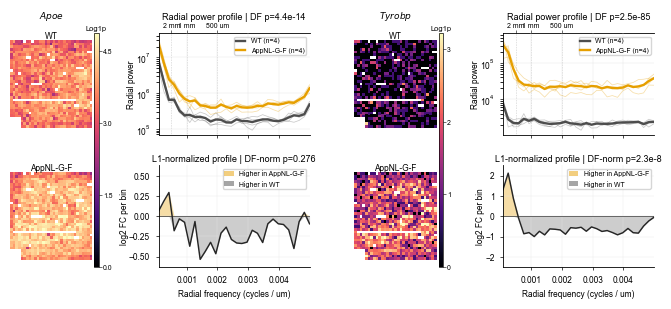

In [7]:
preview_subplot_panel(plot_ad_main_gene_examples, figsize=(7, 3))

#### DE, DF and DF-norm comparison

In [8]:
TEST_COLORS = {"DE": "#7f7f7f", "DF": "#1f77b4", "DF_norm": "#d62728"}
DENOVO_DF_HITS = ["Lrrc17", "Ift46", "Cpe", "Cpne6", "Nefh", "Penk"]
DF_NORM_PATHWAY_HITS = ["Vamp2", "Syt11", "Calm2"] # synaptic vesicle genes
DF_PATHWAY_HITS = ["Gusb", "Trem2", "Fcer1g"] # lysosome, microglia, antigen presentation

def _clip_for_scatter(values, cap):
    """Clip plotted -log10 p-values and return a mask of clipped points."""
    values = np.asarray(values, dtype=float)
    if cap is None:
        return values, np.zeros(values.shape, dtype=bool)
    clipped = values > cap
    return np.minimum(values, cap), clipped


def _test_key_from_col(col):
    """Map p-value column names to test labels."""
    return {"P_DE": "DE", "P_DF": "DF", "P_DF_norm": "DF_norm"}[col]


def _scatter_spearman(df, x_col, y_col):
    """Compute Spearman correlation between two -log10 p-value columns."""
    x = pd.to_numeric(df[x_col], errors="coerce").to_numpy(float)
    y = pd.to_numeric(df[y_col], errors="coerce").to_numpy(float)
    valid = np.isfinite(x) & np.isfinite(y) & (x > 0) & (y > 0)
    if valid.sum() < 3:
        return np.nan
    x_score = -np.log10(np.maximum(x[valid], 1e-300))
    y_score = -np.log10(np.maximum(y[valid], 1e-300))
    return float(pd.Series(x_score).corr(pd.Series(y_score), method="spearman"))

def _normalize_gene_groups(groups):
    """Helper function to normalize gene group specifications."""
    if groups is None:
        return []
    if isinstance(groups, dict):
        groups = [
            {"label": label, **spec} if isinstance(spec, dict) else {"label": label, "genes": spec}
            for label, spec in groups.items()
        ]

    normalized = []
    for spec in groups:
        if isinstance(spec, dict):
            group = dict(spec)
        else:
            label, genes, *rest = spec
            group = {"label": label, "genes": genes}
            if rest:
                group["color"] = rest[0]
            if len(rest) > 1:
                group["marker"] = rest[1]
        group.setdefault("genes", ())
        group.setdefault("label", None)
        group.setdefault("marker", "o")
        group.setdefault("s", group.pop("size", 10))
        group.setdefault("alpha", 0.95)
        group.setdefault("linewidths", 0.35)
        group.setdefault("annotate", False)

        color = group.get("color", "#1f77b4")
        group.setdefault("facecolors", group.get("facecolor", color))
        group.setdefault(
            "edgecolors",
            group.get("edgecolor", "black" if group["facecolors"] != "none" else color),
        )
        group.setdefault("text_color", "0.05")
        normalized.append(group)
    return normalized

def plot_pair_pvalue_scatter(
    ax,
    x_col,
    y_col,
    x_label,
    y_label,
    title,
    *,
    x_cap=None,
    y_cap=None,
    gene_groups=None,
    show_legend=False,
    square=True,
    adjust_labels=True,
):
    """Plot pairwise -log10 p-values with grouped gene highlighting and adjusted labels."""
    # Load test results and FDR counts
    df = _panel_real("ad_pig")
    counts = _fdr_counts("ad_pig")

    # Draw the background scatter plot
    x_raw = _neglog10(df[x_col])
    y_raw = _neglog10(df[y_col])
    x, x_clipped = _clip_for_scatter(x_raw, x_cap)
    y, y_clipped = _clip_for_scatter(y_raw, y_cap)

    ax.scatter(x, y, s=4, color="0.8", alpha=0.4, linewidths=0)

    # Highlight selected genes per group
    texts = []
    text_x = []
    text_y = []
    seen_labels = set()

    for group in _normalize_gene_groups(gene_groups):
        genes = tuple(group["genes"])
        sub = df[df["Feature"].isin(genes)].copy()
        if sub.empty:
            continue

        hx, _ = _clip_for_scatter(_neglog10(sub[x_col]), x_cap)
        hy, _ = _clip_for_scatter(_neglog10(sub[y_col]), y_cap)

        # Group label starting with underscore should be hidden from the legend
        legend_label = group.get("legend_label", group["label"])
        if legend_label is not None and legend_label.startswith("_"):
            legend_label = None

        ax.scatter(
            hx,
            hy,
            s=group["s"],
            marker=group["marker"],
            facecolors=group["facecolors"],
            edgecolors=group["edgecolors"],
            linewidths=group["linewidths"],
            alpha=group["alpha"],
            label=legend_label,
            zorder=group.get("zorder", 5),
        )

        # Add gene name annotation per group
        label_genes = group.get("label_genes", genes if group.get("annotate") else ())
        for gene in label_genes:
            if gene in seen_labels:
                continue
            row = sub[sub["Feature"] == gene]
            if row.empty:
                continue

            gx, _ = _clip_for_scatter(_neglog10(row[x_col]), x_cap)
            gy, _ = _clip_for_scatter(_neglog10(row[y_col]), y_cap)
            gx = float(gx[0])
            gy = float(gy[0])

            txt = ax.text(
                gx,
                gy,
                gene,
                fontsize=group.get("text_size", 6),
                fontstyle=group.get("fontstyle", "italic"),
                color=group["text_color"],
                ha="center",
                va="center",
                zorder=group.get("text_zorder", 8),
                clip_on=False,
            )
            texts.append(txt)
            text_x.append(gx)
            text_y.append(gy)
            seen_labels.add(gene)

    # Add the pval=0.05 lines
    thr = -math.log10(0.05)
    ax.axvline(thr, color="0.5", lw=0.5, ls="--", zorder=0)
    ax.axhline(thr, color="0.5", lw=0.5, ls="--", zorder=0)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

    # Add the title with Spearman correlation and FDR counts
    x_key = _test_key_from_col(x_col)
    y_key = _test_key_from_col(y_col)
    rho = _scatter_spearman(df, x_col, y_col)
    rho_label = "$\rho$=NA" if not np.isfinite(rho) else r"($\rho$=" + f"{rho:.2f})"
    title_counts = (
        f"Number of FDR<0.05: {TEST_DISPLAY[x_key]} {counts[x_key]:,}, "
        f"{TEST_DISPLAY[y_key]} {counts[y_key]:,}"
    )
    ax.set_title(f"{title} {rho_label}\n{title_counts}", fontsize=6.5, pad=3)

    xmax = x_cap if x_cap is not None else max(float(np.nanmax(x_raw)), 1.0)
    ymax = y_cap if y_cap is not None else max(float(np.nanmax(y_raw)), 1.0)
    xlim = xmax * 1.03
    ylim = ymax * 1.04
    diag_lim = min(xlim, ylim)

    ax.plot([0, diag_lim], [0, diag_lim], color="0.5", lw=0.5, zorder=0)
    ax.set_xlim(0, xlim)
    ax.set_ylim(0, ylim)

    # Adjust the position of the text labels to avoid overlap
    if adjust_labels and texts:
        from adjustText import adjust_text

        adjust_text(
            texts,
            x=text_x,
            y=text_y,
            ax=ax,
            expand=(1.1, 1.2),
            force_text=(0.5, 0.5),
            force_static=(0.5, 0.5),
            force_pull=(0.01, 0.02),
            arrowprops=dict(arrowstyle="-", lw=0.5, color="0.35", shrinkA=0, shrinkB=2),
        )

    if square:
        ax.set_box_aspect(1)

    # Add a "capped" label if the data was clipped
    if y_clipped.any() and y_cap is not None and y_cap >= 20:
        ax.text(
            0.02 * xlim,
            y_cap,
            "capped",
            ha="left",
            va="bottom",
            fontsize=5,
            color="0.35",
            clip_on=False,
        )
    if x_clipped.any() and x_cap is not None and x_cap >= 20:
        ax.text(
            x_cap,
            0.02 * ylim,
            "capped",
            ha="center",
            va="bottom",
            fontsize=5,
            color="0.35",
            clip_on=False,
        )

    if show_legend:
        ax.legend(
            frameon=False,
            loc="lower left",
            bbox_to_anchor=(0.0, 0.0),
            fontsize=5,
            handletextpad=0.35,
            borderaxespad=0,
        )

    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)


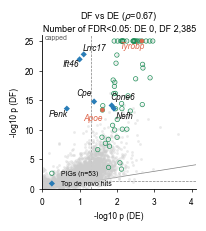

In [9]:
gene_groups = (
    {
        "label": "PIGs (n=53)",
        "genes": AD_PIG_POS_CONTROLS,
        "marker": "o",
        "s": 10,
        "facecolors": "none",
        "edgecolors": "#178a52",
        "linewidths": 0.5,
        "annotate": False,
    },
    {
        "label": "Top de novo hits",
        "genes": DENOVO_DF_HITS,
        "marker": "D",
        "s": 10,
        "facecolors": TEST_COLORS["DF"],
        "edgecolors": "none",
        "linewidths": 0.0,
        "annotate": True,
        "show_in_legend": True,
    },
    {
        "label": "_example",
        "genes": ("Apoe", "Tyrobp"),
        "marker": "o",
        "s": 10,
        "text_color": "#DE6449",
        "facecolors": "#DE6449",
        "edgecolors": "none",
        "linewidths": 0.0,
        "annotate": True,
        "show_in_legend": True,
    },
)
fig, ax = plt.subplots(figsize=(2, 2))
plot_pair_pvalue_scatter(
    ax,
    "P_DE",
    "P_DF",
    "-log10 p (DE)",
    "-log10 p (DF)",
    "DF vs DE",
    x_cap=4,
    y_cap=25,
    gene_groups=gene_groups,
    show_legend=True,
)
plt.show()

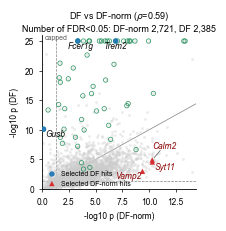

In [10]:
gene_groups = (
    {
        "label": "_PIGs (n=53)",
        "genes": AD_PIG_POS_CONTROLS,
        "marker": "o",
        "s": 10,
        "facecolors": "none",
        "edgecolors": "#178a52",
        "linewidths": 0.5,
        "annotate": False,
    },
    {
        "label": "Selected DF hits",
        "genes": DF_PATHWAY_HITS,
        "marker": "o",
        "s": 15,
        "facecolors": TEST_COLORS["DF"],
        "edgecolors": "none",
        "linewidths": 0.0,
        "annotate": True,
    },
    {
        "label": "Selected DF-norm hits",
        "genes": DF_NORM_PATHWAY_HITS,
        "marker": "^",
        "s": 15,
        "text_color": "darkred",
        "facecolors": TEST_COLORS["DF_norm"],
        "edgecolors": "none",
        "linewidths": 0.0,
        "annotate": True,
    },
)
fig, ax = plt.subplots(figsize=(2, 2))
plot_pair_pvalue_scatter(
    ax,
    "P_DF_norm",
    "P_DF",
    "-log10 p (DF-norm)",
    "-log10 p (DF)",
    "DF vs DF-norm",
    x_cap=14,
    y_cap=25,
    gene_groups=gene_groups,
    show_legend=True,
)
plt.show()

#### Pathway enrichment DF vs DF-norm contrast

In [11]:
# Load precomputed AD/PIG enrichment contrasts
def load_ad_pig_enrichment_contrasts(variant=None):
    """Load cached AD/PIG DF-vs-DF-norm pathway enrichment contrasts."""
    path = RESULT_DIR / AD_ENRICH_CONTRAST_FILE
    if not path.exists():
        return pd.DataFrame()

    if variant is None:
        variant = f"top{AD_PIG_ENRICHMENT_TOP_N}"

    df = pd.read_csv(path)
    df = df[df["panel"].eq("ad_pig") & df["variant"].eq(variant)].copy()

    numeric_cols = (
        "abs_delta",
        "stronger_score",
        "score_DF",
        "score_DF_norm",
        "delta_norm_minus_DF",
        "intersection_size_DF",
        "intersection_size_DF_norm",
        "p_adjust_DF",
        "p_adjust_DF_norm",
    )
    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0.0)

    return df


AD_ENRICHMENT_CONTRASTS = load_ad_pig_enrichment_contrasts()

# Visualization helper functions
def _wrap_term_label(name, width=40, max_lines=2):
    """Wrap pathway labels to at most two compact lines."""
    lines = textwrap.wrap(str(name), width=width)
    if len(lines) <= max_lines:
        return "\n".join(lines)
    return "\n".join(lines[: max_lines - 1] + [lines[max_lines - 1] + "..."])

def _enrichment_bar_colors(plot_df, test, alpha=0.05):
    """Use lighter bars for non-significant enrichment results."""
    base = mpl.colors.to_rgb(TEST_COLORS[test])
    # # Lighten the base color for better visibility
    # base = tuple(np.asarray(base) + (1 - np.asarray(base)) * 0.2)
    # Further lighten the color for non-significant results
    pale = tuple(np.asarray(base) + (1 - np.asarray(base)) * 0.7)
    p_adj = pd.to_numeric(plot_df[f"p_adjust_{test}"], errors="coerce").fillna(1.0)
    return [base if p <= alpha else pale for p in p_adj]

def plot_enrichr_style_ad(ax, n_each=3):
    """Draw AD/PIG DF-vs-DF-norm pathway contrasts."""
    plot_df = AD_ENRICHMENT_CONTRASTS.copy()
    if plot_df.empty:
        ax.axis("off")
        ax.text(0.5, 0.5, "enrichment cache missing", ha="center", va="center", fontsize=6)
        return

    # Keep all KEGG terms and clusterProfiler-simplfied GO terms
    keep = (
        plot_df.get("semantic_simplified_DF", False).astype(bool)
        | plot_df.get("semantic_simplified_DF_norm", False).astype(bool)
        | plot_df.get("source_DF", "").eq("KEGG")
        | plot_df.get("source_DF_norm", "").eq("KEGG")
    )
    # Remove COVID-19 related terms
    covid = plot_df["name"].astype(str).str.contains("covid|coronavirus", case=False, regex=True, na=False)
    plot_df = plot_df[keep & ~covid].copy()

    plot_df["display_name"] = plot_df.get("display_name", plot_df["name"]).fillna(plot_df["name"])
    plot_df = (
        pd.concat(
            [
                plot_df.sort_values("delta_norm_minus_DF", ascending=True).head(n_each),
                plot_df.sort_values("delta_norm_minus_DF", ascending=False).head(n_each),
            ]
        )
        .drop_duplicates("name")
        .sort_values("delta_norm_minus_DF", kind="stable")
        .reset_index(drop=True)
    )

    # Bar plot
    y = np.arange(len(plot_df), dtype=float)
    df_score = plot_df["score_DF"].to_numpy(float)
    norm_score = plot_df["score_DF_norm"].to_numpy(float)
    ax.barh(y, -df_score, height=0.60, color=_enrichment_bar_colors(plot_df, "DF"), alpha=0.7)
    ax.barh(y, norm_score, height=0.60, color=_enrichment_bar_colors(plot_df, "DF_norm"), alpha=0.7)
    ax.axvline(0, color="0.25", lw=0.5)

    # Label the intersection size per term
    xmax = max(float(np.nanmax(df_score)), float(np.nanmax(norm_score)), 1.0) * 1.30
    ax.set_xlim(-xmax, xmax)
    ax.set_yticks([])

    left_count_x, right_count_x = -0.88 * xmax, 0.88 * xmax
    for yi, row in zip(y, plot_df.itertuples(index=False)):
        ax.text(0, yi, _wrap_term_label(row.display_name, width=45), ha="center", va="center", fontsize=5)
        ax.text(left_count_x, yi, f"( {int(row.intersection_size_DF):d} )", ha="center", va="center", fontsize=5)
        ax.text(right_count_x, yi, f"( {int(row.intersection_size_DF_norm):d} )", ha="center", va="center", fontsize=5)

    ticks = np.arange(-math.floor(xmax / 2) * 2, math.floor(xmax / 2) * 2 + 0.1, 4)
    ticks = ticks[(ticks >= -xmax) & (ticks <= xmax)]
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{abs(t):g}" for t in ticks])
    ax.set_xlabel("-log10 BH-adjusted p", labelpad=1)
    ax.set_title("Pathway enrichment analysis\nTop100 genes contrasts", fontsize=6.5, pad=3)

    header_y = y[-1] + 0.9
    ax.set_ylim(y[0] - 0.5, header_y + 0.3)
    ax.text(left_count_x, header_y, "DF top100\n(intersection size)", color=TEST_COLORS["DF"],
            ha="center", va="top", fontsize=5.5, linespacing=0.90)
    ax.text(right_count_x, header_y, "DF-norm top100\n(intersection size)", color=TEST_COLORS["DF_norm"],
            ha="center", va="top", fontsize=5.5, linespacing=0.90)

    for spine in ("top", "right", "left"):
        ax.spines[spine].set_visible(False)

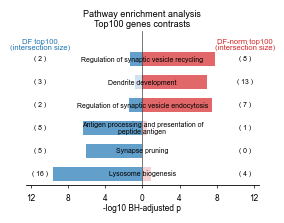

In [12]:
fig, ax = plt.subplots(figsize=(3, 2))
plot_enrichr_style_ad(ax, n_each=3)
plt.show()

In [13]:
plot_df = AD_ENRICHMENT_CONTRASTS.copy()
# Keep all KEGG terms and clusterProfiler-simplfied GO terms
keep = (
    plot_df.get("semantic_simplified_DF", False).astype(bool)
    | plot_df.get("semantic_simplified_DF_norm", False).astype(bool)
    | plot_df.get("source_DF", "").eq("KEGG")
    | plot_df.get("source_DF_norm", "").eq("KEGG")
)
# Remove COVID-19 related terms
covid = plot_df["name"].astype(str).str.contains("covid|coronavirus", case=False, regex=True, na=False)
plot_df = plot_df[keep & ~covid].copy()


In [14]:
# Top DF pathways
plot_df.sort_values("delta_norm_minus_DF", ascending=True).head(5)

,panel,variant,term_key,source_DF,native_DF,name_DF,display_name_DF,description_DF,term_size_DF,effective_domain_size_DF,...,description,term_size,effective_domain_size,delta_norm_minus_DF,abs_delta,direction,stronger_score,stronger_p_adjust,stronger_hit_genes,rank_abs_delta
0,ad_pig,top100,KEGG:mmu04142,KEGG,mmu04142,Lysosome biogenesis,Lysosome biogenesis,Lysosome biogenesis,254.0,11172.0,...,Lysosome biogenesis,254.0,11172.0,-8.644295,8.644295,DF,9.618307,2.408200e-10,Ctsd/Hexb/Ctss/Ctsz/Laptm5/Hexa/Ctsb/Ctsl/Ctsh...,1
4,ad_pig,top100,GO:BP:GO:0098883,GO:BP,GO:0098883,synapse pruning,Synapse pruning,synapse pruning,19.0,25730.0,...,synapse pruning,19.0,25730.0,-6.017620,6.017620,DF,6.017620,9.602405e-07,Trem2/C1qa/C1qb/C1qc/Cx3cr1,5
6,ad_pig,top100,GO:BP:GO:0048002,GO:BP,GO:0048002,antigen processing and presentation of peptide...,Antigen processing and presentation of peptide...,antigen processing and presentation of peptide...,88.0,25730.0,...,antigen processing and presentation of peptide...,88.0,25730.0,-5.898430,5.898430,DF,6.362532,4.339788e-07,Trem2/Mpeg1/B2m/Ctss/Fcer1g/Fcgr3/H2-K1/Ctsl,7
11,ad_pig,top100,GO:BP:GO:0002697,GO:BP,GO:0002697,regulation of immune effector process,Regulation of immune effector process,regulation of immune effector process,494.0,25730.0,...,regulation of immune effector process,494.0,25730.0,-5.344357,5.344357,DF,5.808458,1.554326e-06,Trem2/Tyrobp/B2m/Fcer1g/Laptm5/Fcgr3/Grn/H2-K1...,12
21,ad_pig,top100,GO:BP:GO:0042590,GO:BP,GO:0042590,antigen processing and presentation of exogeno...,Antigen processing and presentation of exogeno...,antigen processing and presentation of exogeno...,14.0,25730.0,...,antigen processing and presentation of exogeno...,14.0,25730.0,-4.945821,4.945821,DF,4.945821,1.132867e-05,Mpeg1/Fcer1g/Fcgr3/H2-K1,22


In [15]:
# Top DF-norm pathways
plot_df.sort_values("delta_norm_minus_DF", ascending=False).head(5)

,panel,variant,term_key,source_DF,native_DF,name_DF,display_name_DF,description_DF,term_size_DF,effective_domain_size_DF,...,description,term_size,effective_domain_size,delta_norm_minus_DF,abs_delta,direction,stronger_score,stronger_p_adjust,stronger_hit_genes,rank_abs_delta
1,ad_pig,top100,GO:BP:GO:1903421,GO:BP,GO:1903421,regulation of synaptic vesicle recycling,Regulation of synaptic vesicle recycling,regulation of synaptic vesicle recycling,46.0,25730.0,...,regulation of synaptic vesicle recycling,46.0,25730.0,6.462361,6.462361,DF-norm,7.801142,1.580730e-08,Actb/Calm1/Syt11/Calm2/Vamp2/Snap91/Actg1/Rac1,2
3,ad_pig,top100,GO:BP:GO:0016358,GO:BP,GO:0016358,dendrite development,Dendrite development,dendrite development,334.0,25730.0,...,dendrite development,334.0,25730.0,6.200694,6.200694,DF-norm,6.965611,1.082402e-07,Ppp3ca/Mef2a/Ywhah/Pak1/Actr2/Ctnnd2/Trak1/Paf...,4
5,ad_pig,top100,GO:BP:GO:1900242,GO:BP,GO:1900242,regulation of synaptic vesicle endocytosis,Regulation of synaptic vesicle endocytosis,regulation of synaptic vesicle endocytosis,37.0,25730.0,...,regulation of synaptic vesicle endocytosis,37.0,25730.0,5.967686,5.967686,DF-norm,7.432299,3.695741e-08,Actb/Calm1/Syt11/Calm2/Snap91/Actg1/Rac1,6
9,ad_pig,top100,GO:BP:GO:0010970,GO:BP,GO:0010970,transport along microtubule,Transport along microtubule,transport along microtubule,196.0,25730.0,...,transport along microtubule,196.0,25730.0,5.413906,5.413906,DF-norm,6.095795,8.020562e-07,Ift46/Kif5c/Hnrnpu/Myo5a/Trak1/Pafah1b1/App/Cd...,10
12,ad_pig,top100,KEGG:mmu04114,KEGG,mmu04114,Oocyte meiosis,Oocyte meiosis,Oocyte meiosis,123.0,11172.0,...,Oocyte meiosis,123.0,11172.0,5.236134,5.236134,DF-norm,5.390847,4.065869e-06,Ppp3ca/Calm1/Calm2/Ywhah/Ppp2r5c/Ppp3r1/Ywhag/...,13


#### Combined row 2

In [16]:
def plot_ad_main_row2(axspec):
    """Draw the two p-value scatters and the pathway contrast panel."""
    row2 = gridspec.GridSpecFromSubplotSpec(
        1, 3,
        subplot_spec=axspec,
        width_ratios=[1, 1, 1.4],
        wspace=0.2,
    )
    gene_groups_left = (
        {
            "label": "PIGs (n=53)",
            "genes": AD_PIG_POS_CONTROLS,
            "marker": "o",
            "s": 10,
            "facecolors": "none",
            "edgecolors": "#178a52",
            "linewidths": 0.5,
            "annotate": False,
        },
        {
            "label": "Top de novo hits",
            "genes": DENOVO_DF_HITS,
            "marker": "D",
            "s": 10,
            "facecolors": TEST_COLORS["DF"],
            "edgecolors": "none",
            "linewidths": 0.0,
            "annotate": True,
            "show_in_legend": True,
        },
        {
            "label": "_example",
            "genes": ("Apoe", "Tyrobp"),
            "marker": "o",
            "s": 10,
            "text_color": "#DE6449",
            "facecolors": "#DE6449",
            "edgecolors": "none",
            "linewidths": 0.0,
            "annotate": True,
            "show_in_legend": True,
        },
    )
    ax1 = plt.gcf().add_subplot(row2[0])
    plot_pair_pvalue_scatter(
        ax1,
        "P_DE",
        "P_DF",
        "-log10 p (DE)",
        "-log10 p (DF)",
        "DF vs DE",
        x_cap=4,
        y_cap=25,
        gene_groups=gene_groups_left,
        show_legend=True,
    )

    gene_groups_right = (
        {
            "label": "_PIGs (n=53)",
            "genes": AD_PIG_POS_CONTROLS,
            "marker": "o",
            "s": 10,
            "facecolors": "none",
            "edgecolors": "#178a52",
            "linewidths": 0.5,
            "annotate": False,
        },
        {
            "label": "Selected DF hits",
            "genes": DF_PATHWAY_HITS,
            "marker": "o",
            "s": 15,
            "text_color": TEST_COLORS["DF"],
            "facecolors": TEST_COLORS["DF"],
            "edgecolors": "none",
            "linewidths": 0.0,
            "annotate": True,
        },
        {
            "label": "Selected DF-norm hits",
            "genes": DF_NORM_PATHWAY_HITS,
            "marker": "^",
            "s": 15,
            "text_color": TEST_COLORS["DF_norm"],
            "facecolors": TEST_COLORS["DF_norm"],
            "edgecolors": "none",
            "linewidths": 0.0,
            "annotate": True,
        },
    )
    ax2 = plt.gcf().add_subplot(row2[1])
    plot_pair_pvalue_scatter(
        ax2,
        "P_DF_norm",
        "P_DF",
        "-log10 p (DF-norm)",
        "-log10 p (DF)",
        "DF vs DF-norm",
        x_cap=14,
        y_cap=25,
        gene_groups=gene_groups_right,
        show_legend=True,
    )

    ax3 = plt.gcf().add_subplot(row2[2])
    plot_enrichr_style_ad(ax3)

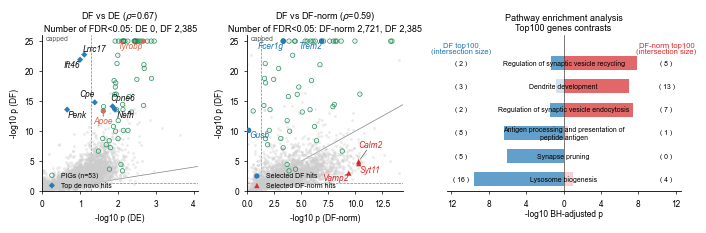

In [17]:
preview_subplot_panel(plot_ad_main_row2, figsize=(7, 2))

#### Save the combined figure

In [18]:
def build_ad_main_figure():
    """Assemble the AD/PIG main figure from the three row helpers."""
    fig = plt.figure(figsize=(182 / 25.4, 178 / 25.4))
    outer = gridspec.GridSpec(
        5, 1,
        figure=fig,
        left=0.05,
        right=0.95,
        top=0.95,
        bottom=0.05,
        height_ratios=[1.5, 0.08, 2, 0.4, 3],
        hspace=0.2,
    )
    plot_pipeline_flat(outer[0])
    plot_ad_main_row2(outer[2])
    plot_ad_main_gene_examples(outer[4])
    return fig

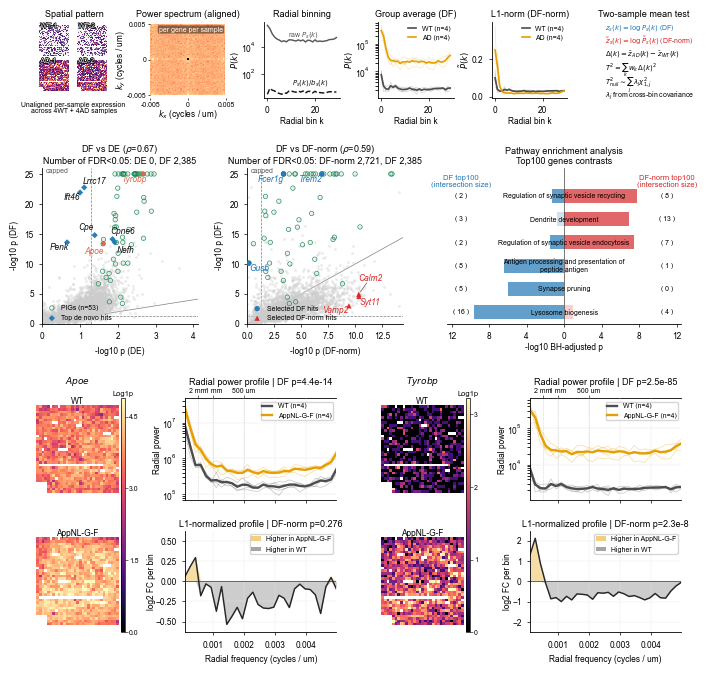

In [19]:
fig = build_ad_main_figure()
plt.show()

In [20]:
fig = build_ad_main_figure()
fig.savefig(FIGURE_DIR / "ad_main.pdf", bbox_inches=None)
plt.close(fig)

### Example genes to highlight

#### Weak PIG genes and de novo DF hits

In [21]:
REAL.query("Feature in @AD_PIG_POS_CONTROLS").sort_values("P_DF", ascending=False).head(10)

test,panel,Feature,P_DE,P_DF,P_DF_norm
2145,ad_pig,Rpl18a,0.007548,4.174272e-04,1.346437e-04
1206,ad_pig,Igfbp5,0.016694,2.172436e-04,3.390526e-05
1047,ad_pig,Gns,0.008291,3.610698e-05,2.021468e-04
1238,ad_pig,Itm2b,0.032548,2.143020e-07,1.609533e-09
1335,ad_pig,Lgmn,0.015764,5.801639e-08,4.695397e-04
453,ad_pig,Cd63,0.020331,1.863714e-08,1.289744e-02
1922,ad_pig,Prdx6,0.016914,3.964609e-09,3.820667e-07
307,ad_pig,Axl,0.009882,1.818720e-09,1.991294e-02
1072,ad_pig,Gpx4,0.025126,1.732024e-09,7.714641e-04
1391,ad_pig,Man2b1,0.011488,1.046669e-10,1.173556e-04


In [22]:
REAL.query("Feature not in @AD_PIG_POS_CONTROLS").sort_values("P_DF", ascending=True).head(10)

test,panel,Feature,P_DE,P_DF,P_DF_norm
1351,ad_pig,Lrrc17,0.077176,1.776478e-23,4.301229e-01
1202,ad_pig,Ift46,0.099442,1.230185e-22,1.702047e-16
1114,ad_pig,Hba-a2,0.126547,7.481443e-22,9.801507e-01
2247,ad_pig,Rps19-ps6,0.015733,5.174779e-17,4.495884e-06
592,ad_pig,Cpe,0.040764,1.639402e-15,8.898998e-06
2225,ad_pig,Rps12,0.006346,6.593661e-15,4.064836e-04
597,ad_pig,Cpne6,0.013784,7.552413e-15,7.019092e-05
2005,ad_pig,RP23-13B8.12,0.003705,2.197867e-14,5.144792e-07
1623,ad_pig,Nefh,0.011990,2.517002e-14,2.044656e-02
1786,ad_pig,Penk,0.218519,2.602577e-14,2.618665e-02


#### DF vs DF-norm pathway contrast highlights

In [23]:
def load_ad_pig_enrichment_contrasts(variant=None):
    """Load cached AD/PIG DF-vs-DF-norm pathway enrichment contrasts."""
    path = RESULT_DIR / AD_ENRICH_CONTRAST_FILE
    if not path.exists():
        return pd.DataFrame()

    if variant is None:
        variant = f"top{AD_PIG_ENRICHMENT_TOP_N}"

    df = pd.read_csv(path)
    df = df[df["panel"].eq("ad_pig") & df["variant"].eq(variant)].copy()

    numeric_cols = (
        "abs_delta",
        "stronger_score",
        "score_DF",
        "score_DF_norm",
        "delta_norm_minus_DF",
        "intersection_size_DF",
        "intersection_size_DF_norm",
        "p_adjust_DF",
        "p_adjust_DF_norm",
    )
    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0.0)

    return df

AD_ENRICHMENT_CONTRASTS = load_ad_pig_enrichment_contrasts()

In [24]:
synaptic_df_hits = AD_ENRICHMENT_CONTRASTS[
    AD_ENRICHMENT_CONTRASTS["display_name_DF_norm"].str.contains('synaptic vesicle') &
    (AD_ENRICHMENT_CONTRASTS["direction"] == "DF-norm")
]['stronger_hit_genes'].str.split('/').values[0]

REAL.query("Feature in @synaptic_df_hits").sort_values("P_DF", ascending=False).head(5)

test,panel,Feature,P_DE,P_DF,P_DF_norm
2904,ad_pig,Vamp2,0.282550,0.001005,4.050361e-10
2624,ad_pig,Syt11,0.132601,0.000027,4.774699e-11
397,ad_pig,Calm2,0.035558,0.000012,4.933669e-11
67,ad_pig,Actb,0.053787,0.000010,6.568033e-14
68,ad_pig,Actg1,0.027303,0.000002,6.527557e-10


In [25]:
lysosome_df_hits = AD_ENRICHMENT_CONTRASTS[
    AD_ENRICHMENT_CONTRASTS["display_name_DF"].str.contains('Lysosome biogenesis') &
    (AD_ENRICHMENT_CONTRASTS["direction"] == "DF")
]['stronger_hit_genes'].str.split('/').values[0]

REAL.query("Feature in @lysosome_df_hits").sort_values("P_DF_norm", ascending=False).head(5)

test,panel,Feature,P_DE,P_DF,P_DF_norm
1098,ad_pig,Gusb,0.005407,7.549924e-11,0.737106
631,ad_pig,Ctsh,0.002093,5.346031e-15,0.028215
1659,ad_pig,Npc2,0.007335,2.619606e-14,0.007663
1321,ad_pig,Laptm5,0.007219,2.089773e-33,0.000456
1391,ad_pig,Man2b1,0.011488,1.046669e-10,0.000117


In [26]:
synapse_pruning_df_hits = AD_ENRICHMENT_CONTRASTS[
    AD_ENRICHMENT_CONTRASTS["display_name_DF"].str.contains('Synapse pruning') &
    (AD_ENRICHMENT_CONTRASTS["direction"] == "DF")
]['stronger_hit_genes'].str.split('/').values[0]

REAL.query("Feature in @synapse_pruning_df_hits").sort_values("P_DF_norm", ascending=False).head(5)

test,panel,Feature,P_DE,P_DF,P_DF_norm
643,ad_pig,Cx3cr1,0.009775,1.750325e-12,1.989593e-04
2763,ad_pig,Trem2,0.003712,1.050897e-89,1.308430e-07
375,ad_pig,C1qb,0.003404,2.058024e-53,8.649409e-08
374,ad_pig,C1qa,0.002802,7.427863e-59,1.038802e-08
376,ad_pig,C1qc,0.006531,1.583112e-45,5.419458e-09


In [27]:
antigen_df_hits = AD_ENRICHMENT_CONTRASTS[
    AD_ENRICHMENT_CONTRASTS["display_name_DF"].str.contains('Antigen processing') &
    (AD_ENRICHMENT_CONTRASTS["direction"] == "DF")
]['stronger_hit_genes'].str.split('/').values[0]

REAL.query("Feature in @antigen_df_hits").sort_values("P_DF_norm", ascending=False).head(5)

test,panel,Feature,P_DE,P_DF,P_DF_norm
1101,ad_pig,H2-K1,0.001295,1.622223e-19,0.024797
929,ad_pig,Fcer1g,0.001321,8.413712e-41,0.000457
1491,ad_pig,Mpeg1,0.003506,4.539427e-43,0.000135
930,ad_pig,Fcgr3,0.010016,2.308042e-23,0.000062
633,ad_pig,Ctss,0.003024,1.931161e-41,0.000036


#### Save final figures

In [28]:
# Select genes to save
# WEAK_PIG_GENES = ["Gns", "Igfbp5", "Rpl18a"]
DENOVO_DF_HITS = ["Lrrc17", "Ift46", "Cpe", "Cpne6", "Nefh", "Penk"]
PATHWAY_HITS = [
    "Vamp2", "Syt11", "Calm2", # DF-norm synaptic vesicle genes
    "Gusb", "Trem2", "Fcer1g" # DF hits
]

# Save de novo DF hits
generate_ad_pig_gene_profile_pdf(
    list(DENOVO_DF_HITS),
    output=FIGURE_DIR / "ad_supp_gene_denovo_df.pdf",
    rows_per_page=6
)

# Save pathway hits
generate_ad_pig_gene_profile_pdf(
    list(PATHWAY_HITS),
    output=FIGURE_DIR / "ad_supp_gene_contrasts.pdf",
    rows_per_page=6
)

### Hyperparameter benchmarking supp figure

#### Binning strategy illustration

In [29]:
GEOM_NULL_CALIB

,panel,scenario_id,normalization,binning,feature_mode,requested_n_radial_bins,n_radial_bins,perm_idx,test,P_value
144960,ad_pig,raw_log_radial_bins26_requested30,raw,log,geometric,30,26,0,DF,0.019799
144961,ad_pig,raw_log_radial_bins26_requested30,raw,log,geometric,30,26,0,DF,0.023818
144962,ad_pig,raw_log_radial_bins26_requested30,raw,log,geometric,30,26,0,DF,0.024584
144963,ad_pig,raw_log_radial_bins26_requested30,raw,log,geometric,30,26,0,DF,0.030310
144964,ad_pig,raw_log_radial_bins26_requested30,raw,log,geometric,30,26,0,DF,0.042049
...,...,...,...,...,...,...,...,...,...,...
507355,ad_pig,log1p_log_radial_bins26_requested30,log1p,log,geometric,30,26,11,DF_norm,1.000000
507356,ad_pig,log1p_log_radial_bins26_requested30,log1p,log,geometric,30,26,11,DF_norm,1.000000
507357,ad_pig,log1p_log_radial_bins26_requested30,log1p,log,geometric,30,26,11,DF_norm,1.000000
507358,ad_pig,log1p_log_radial_bins26_requested30,log1p,log,geometric,30,26,11,DF_norm,1.000000


In [30]:
def _get_ad_geometric_comparator():
    """Get the geometric comparator with spectra."""
    global ad_cmp_geom, ad_paths_geom, ad_wt_idx_geom, ad_tg_idx_geom
    if "ad_cmp_geom" not in globals():
        geom_edges = _geometric_frequency_edges(np.asarray(ad_cmp.freq_edges), ad_cmp)
        ad_cmp_geom, ad_paths_geom = fit_all_samples(
            ad_samples,
            ad_genes,
            "radial",
            freq_edges=geom_edges,
        )
        ad_wt_idx_geom, ad_tg_idx_geom = _binary_indices(ad_real, ad_paths_geom)
    return ad_cmp_geom, ad_paths_geom, ad_wt_idx_geom, ad_tg_idx_geom


def _radial_profile_axis_for_binning(cmp, *, geometric=False):
    """Helper function to compute the radial profile axis for a given comparator."""
    k = cmp.spectra_.shape[-1]
    edges = np.asarray(getattr(cmp, "freq_edges", []), dtype=float)
    if len(edges) == k + 1:
        lo, hi = edges[:-1], edges[1:]
    elif len(edges) == k + 2:
        lo, hi = edges[1:-1], edges[2:]
    else:
        return np.arange(k, dtype=float), "Radial frequency (a.u.)"
    lo = np.asarray(lo, dtype=float)
    hi = np.asarray(hi, dtype=float)
    if geometric and np.all(lo > 0) and np.all(hi > 0):
        centers = np.sqrt(lo * hi)
    else:
        centers = 0.5 * (lo + hi)
    centers = np.asarray(centers, dtype=float)
    if np.any(centers <= 0):
        positive = centers[centers > 0]
        centers = np.where(centers <= 0, positive.min() * 0.5 if positive.size else 1.0, centers)
    return 1000.0 * centers, "Radial frequency (cycles/mm)"


def _plot_binning_gene_profile(
    ax,
    cmp,
    wt_idx,
    tg_idx,
    gene,
    *,
    geometric=False,
    normalize_shape=False,
    title=None,
    ylabel=False,
    legend=False,
):
    """Plot the binning profile for a given gene in the comparator."""
    # Parse the x-axis frequency edges
    x, xlabel = _radial_profile_axis_for_binning(cmp, geometric=geometric)

    # Select the gene and samples to plot
    gi = ad_genes.index(gene)
    wt = np.maximum(cmp.spectra_[wt_idx, gi, :], 1e-12)
    tg = np.maximum(cmp.spectra_[tg_idx, gi, :], 1e-12)
    if normalize_shape:
        wt = wt / np.maximum(wt.sum(axis=1, keepdims=True), 1e-12)
        tg = tg / np.maximum(tg.sum(axis=1, keepdims=True), 1e-12)
    wt_color = GROUP_COLORS["WT"]
    tg_color = GROUP_COLORS["AD"]

    # Draw the curve for radial power profiles
    mean_marker = "^" if geometric else "o"
    ylim_values = []
    for y, color, alpha in ((wt, wt_color, 0.18), (tg, tg_color, 0.20)):
        plot_y = y.copy()
        finite = plot_y[np.isfinite(plot_y) & (plot_y > 0)]
        if finite.size:
            ylim_values.append(finite)
        for row in plot_y:
            ax.plot(x, row, color=color, alpha=alpha, lw=0.45)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=RuntimeWarning)
            mean_y = np.nanmean(plot_y, axis=0)
        label = f"WT (n={len(wt)})" if color == wt_color else f"AD (n={len(tg)})"
        ax.plot(
            x,
            mean_y,
            color=color,
            lw=1.20,
            marker=mean_marker,
            ms=2.0,
            markevery=max(1, len(x) // 7),
            mec=color,
            mfc="white",
            mew=0.45,
            label=label,
        )

    # Adjust axis scale and limits
    ax.set_yscale("log")
    if geometric:
        ax.set_xscale("log")
    if ylim_values:
        vals = np.concatenate(ylim_values)
        ax.set_ylim(vals.min() * 0.65, vals.max() * 1.65)

    # Add labels and title
    ax.set_xlabel(xlabel, labelpad=1)
    ax.set_ylabel(("L1-normalized P(k)" if normalize_shape else "P(k)") if ylabel else "", labelpad=1)
    if title is None:
        title = f"{gene} {'log-bin' if geometric else 'linear-bin'} {'DF-norm' if normalize_shape else 'DF'}"
    ax.set_title(title, fontsize=6, pad=2)
    if legend:
        ax.legend(frameon=False, fontsize=5, loc="upper right", handlelength=1.2)
    ax.grid(color="0.90", lw=0.35, alpha=0.75)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


def plot_binning_profile_comparison(axspec, gene="Tyrobp"):
    """Draw one-gene linear/log-bin DF and DF-norm profile examples."""
    fig = plt.gcf()
    cmp_geom, _paths_geom, wt_idx_geom, tg_idx_geom = _get_ad_geometric_comparator()
    gs = gridspec.GridSpecFromSubplotSpec(1, 4, subplot_spec=axspec, wspace=0.32)
    panels = (
        (ad_cmp, ad_wt_idx, ad_tg_idx, False, False, f"$\\it{{{gene}}}$ linear-bin DF"),
        (ad_cmp, ad_wt_idx, ad_tg_idx, False, True, f"$\\it{{{gene}}}$ linear-bin DF-norm"),
        (cmp_geom, wt_idx_geom, tg_idx_geom, True, False, f"$\\it{{{gene}}}$ log-bin DF"),
        (cmp_geom, wt_idx_geom, tg_idx_geom, True, True, f"$\\it{{{gene}}}$ log-bin DF-norm"),
    )
    for i, (cmp_i, wt_i, tg_i, geometric, normalize_shape, title) in enumerate(panels):
        ax = fig.add_subplot(gs[0, i])
        _plot_binning_gene_profile(
            ax,
            cmp_i,
            wt_i,
            tg_i,
            gene,
            geometric=geometric,
            normalize_shape=normalize_shape,
            title=title,
            ylabel=(i in (0, 1)),
            legend=(i == 0),
        )

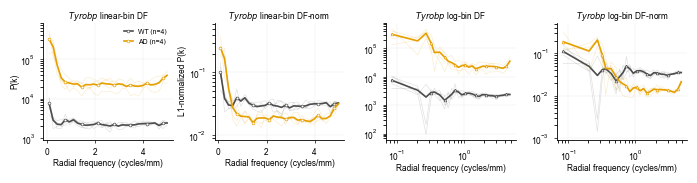

In [31]:
preview_subplot_panel(plot_binning_profile_comparison, figsize=(7, 1.5))

#### Null calibration

In [32]:
def _ecdf_values(p_values):
    xs = np.sort(np.clip(np.asarray(p_values, dtype=float), 0.0, 1.0))
    ys = np.arange(1, len(xs) + 1) / len(xs)
    return xs, ys


def _plot_null_ecdf_panel(ax, panel, test, title, ylabel=False, legend=False, binning="linear"):
    """Helper function to plot empirical null ECDF for a given panel and test."""
    # Set group plotting styles
    raw_radial_label = f"Raw {'log-bin' if binning == 'log' else RADIAL_LABEL}"
    log_radial_label = f"Log1p {'log-bin' if binning == 'log' else RADIAL_LABEL}"
    styles = [
        ("raw", "radial", "#0072B2", "-", raw_radial_label),
        ("raw", "2d", "#009E73", "--", "Raw 2D"),
        ("log1p", "radial", "#D55E00", "-", log_radial_label),
        ("log1p", "2d", "#CC79A7", "--", "Log1p 2D"),
    ]

    # Compute the empirical p-value CDF and the false positive rate per group
    fprs = {}
    for normalization, mode, color, ls, label in styles:
        sub = NULL_CALIB_ALL[
            (NULL_CALIB_ALL["panel"] == panel)
            & (NULL_CALIB_ALL["normalization"] == normalization)
            & (NULL_CALIB_ALL["binning"] == binning)
            & (NULL_CALIB_ALL["test"] == test)
            & (NULL_CALIB_ALL["feature_mode"] == mode)
        ]
        xs, ys = _ecdf_values(sub["P_value"])
        fprs[label] = float((sub["P_value"].to_numpy(float) < 0.05).mean()) if len(sub) else np.nan
        ax.step(xs, ys, where="post", color=color, ls=ls, lw=1.05, label=label)
    ax.plot([0, 1], [0, 1], color="0.72", lw=0.7, ls=":", zorder=0)
    ax.axvline(0.05, color="0.82", lw=0.7)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    # Add title, axis labels, and text annotations
    ax.set_title(title, fontsize=6.5, pad=2)
    ax.set_xlabel("Null p-value", labelpad=1)
    if ylabel:
        ax.set_ylabel("Empirical CDF", labelpad=1)
    else:
        ax.set_ylabel("")
    ax.text(
        0.05,
        0.95,
        "False positive rate @ 0.05\n"
        f"Raw radial: {fprs[raw_radial_label]:.3f}\n"
        f"Raw 2D: {fprs['Raw 2D']:.3f}\n"
        f"Log1p radial: {fprs[log_radial_label]:.3f}\n"
        f"Log1p 2D: {fprs['Log1p 2D']:.3f}\n",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=5,
    )
    if legend:
        ax.legend(frameon=False, fontsize=5, loc="lower right", handlelength=1.8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


def plot_null_ecdf_comparison_row(axspec):
    """Draw empirical null ECDF panels for linear/log-bin tests."""
    fig = plt.gcf()
    gs = gridspec.GridSpecFromSubplotSpec(1, 4, subplot_spec=axspec, wspace=0.32)
    panels = [
        ("Linear-bin DF", "DF", "linear"),
        ("Linear-bin DF-norm", "DF_norm", "linear"),
        ("Log-bin DF", "DF", "log"),
        ("Log-bin DF-norm", "DF_norm", "log"),
    ]
    for i, (title, test, binning) in enumerate(panels):
        ax = fig.add_subplot(gs[0, i])
        _plot_null_ecdf_panel(
            ax,
            "ad_pig",
            test,
            title,
            ylabel=(i == 0),
            legend=(i == 0),
            binning=binning,
        )
        if i > 0:
            ax.set_ylabel("")

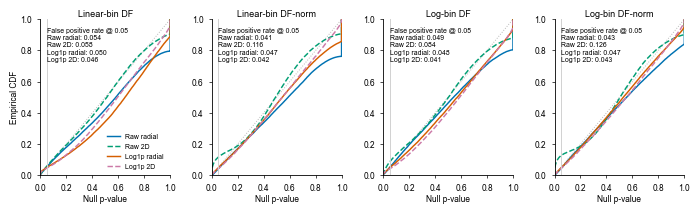

In [33]:
preview_subplot_panel(plot_null_ecdf_comparison_row, figsize=(7, 2))

#### Sensitivity to positive controls

In [34]:
#### Positive control styles
POSITIVE_CONTROL_STYLES = [
    ("Raw radial", "raw", "radial", "#0072B2", "o"),
    ("Raw 2D", "raw", "2d", "#009E73", "s"),
    ("Log1p radial", "log1p", "radial", "#D55E00", "^"),
    ("Log1p 2D", "log1p", "2d", "#CC79A7", "D"),
]

def _scenario_test_series(input_transform, binning, feature_mode, test):
    """Extract PIG gene p-values for a specific scenario."""
    sub = FULL_TESTS[
        FULL_TESTS["panel"].eq("ad_pig")
        & FULL_TESTS["input"].eq(input_transform)
        & FULL_TESTS["binning"].eq(binning)
        & FULL_TESTS["feature_mode"].eq(feature_mode)
        & FULL_TESTS["test"].eq(test)
        & FULL_TESTS["requested_n_radial_bins"].eq(AD_PIG_REFERENCE_N_RADIAL_BINS)
    ]
    if sub.empty:
        return pd.Series(dtype=float)
    return sub.set_index("Feature")["P_value"].astype(float)


def _positive_control_order(genes):
    """Determine the order of PIG genes based on their max test p-values in the linear binning mode."""
    present = [g for g in genes if g in set(FULL_TESTS["Feature"])]
    scores = pd.Series(0.0, index=present, dtype=float)
    for test in ("DF", "DF_norm"):
        for _label, input_transform, feature_mode, _color, _marker in POSITIVE_CONTROL_STYLES:
            vals = _scenario_test_series(input_transform, "linear", feature_mode, test).reindex(present)
            scores = np.maximum(scores, _neglog10(vals.fillna(1.0).to_numpy(float)))
    return pd.Series(scores, index=present).sort_values(ascending=True).index.tolist()


def _positive_control_xlim(gene_order):
    """Compute the shared x-axis limit for the positive control plots."""
    max_score = 0.0
    for binning in ("linear", "log"):
        for test in ("DF", "DF_norm"):
            for _label, input_transform, feature_mode, _color, _marker in POSITIVE_CONTROL_STYLES:
                vals = _scenario_test_series(input_transform, binning, feature_mode, test).reindex(gene_order)
                if len(vals):
                    finite = _neglog10(vals.fillna(1.0).to_numpy(float))
                    if np.isfinite(finite).any():
                        max_score = max(max_score, float(np.nanmax(finite)))
    return max(2.1, min(60.0, max_score * 1.04))


def _plot_positive_control_pvalues(ax, binning, test, title, gene_order, *, show_legend=False, xmax=None):
    """Plot the p-values for the positive control genes."""
    # Plot the p-value for each gene in each testing scenario
    y = np.arange(len(gene_order))
    offsets = np.linspace(-0.27, 0.27, len(POSITIVE_CONTROL_STYLES))
    for offset, (label, input_transform, feature_mode, color, marker) in zip(offsets, POSITIVE_CONTROL_STYLES, strict=True):
        # Extract the p-values for the current scenario and reorder them
        vals = _scenario_test_series(input_transform, binning, feature_mode, test).reindex(gene_order)
        x = _neglog10(vals.fillna(1.0).to_numpy(float))
        ax.scatter(
            x,
            y + offset,
            s=6,
            marker=marker,
            color=color,
            edgecolors="none",
            linewidths=0,
            alpha=0.88,
            label=label,
        )

    # Remove the y-axis gene name labels
    ax.set_yticks(y)
    ax.set_yticklabels([])
    ax.tick_params(axis="y", length=1.5, width=0.5, color="0.45")

    ax.set_ylim(-0.8, len(gene_order) - 0.2)
    ax.set_xlim(0, xmax if xmax is not None else None)

    # Add axis labels and plot title
    ax.set_ylabel("PIGs (n=53) as positive controls", labelpad=1)
    ax.set_xlabel("-log10 p-value", labelpad=1)
    ax.set_title(title, fontsize=6, pad=2)
    ax.grid(axis="x", color="0.90", lw=0.35, alpha=0.70)
    if show_legend:
        ax.legend(
            frameon=False,
            fontsize=5,
            loc="lower right",
            handletextpad=0.25,
            borderaxespad=0.05,
            labelspacing=0.22,
        )
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

def plot_positive_control_sensitivity_row(axspec):
    """Draw PIG positive-control p-value sensitivity panels."""
    fig = plt.gcf()
    gs = gridspec.GridSpecFromSubplotSpec(1, 4, subplot_spec=axspec, wspace=0.18)
    linear_order = _positive_control_order(AD_PIG_POS_CONTROLS)
    xmax = _positive_control_xlim(linear_order)
    panels = [
        ("Linear-bin DF", "linear", "DF"),
        ("Linear-bin DF-norm", "linear", "DF_norm"),
        ("Log-bin DF", "log", "DF"),
        ("Log-bin DF-norm", "log", "DF_norm"),
    ]
    for i, (title, binning, test) in enumerate(panels):
        ax = fig.add_subplot(gs[0, i])
        _plot_positive_control_pvalues(
            ax,
            binning,
            test,
            title,
            linear_order,
            show_legend=(i == 0),
            xmax=xmax,
        )
        if i > 0:
            ax.set_ylabel("")

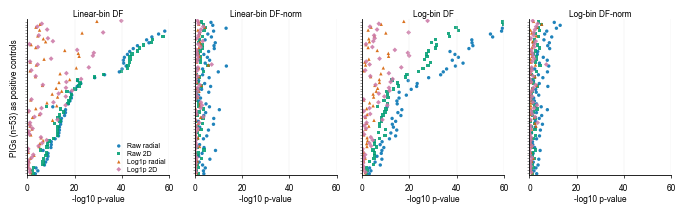

In [35]:
preview_subplot_panel(plot_positive_control_sensitivity_row, figsize=(7, 2))

#### Robustness across number of bins

In [36]:
def _robustness_style(test, binning):
    styles = {
        ("DF", "linear"): (TEST_COLORS["DF"], "o", "-"),
        ("DF", "geometric"): (TEST_COLORS["DF"], "^", "-"),
        ("DF_norm", "linear"): (TEST_COLORS["DF_norm"], "o", "-"),
        ("DF_norm", "geometric"): (TEST_COLORS["DF_norm"], "^", "-"),
    }
    return styles[(test, binning)]

def _sample_rank_long(df):
    rows = []
    keep = df.drop_duplicates(["binning", "requested_n_radial_bins", "n_frequency_bins"])
    for row in keep.itertuples(index=False):
        values = np.asarray(json.loads(row.sample_effective_rank_values), dtype=float)
        samples = list(json.loads(row.sample_effective_rank_samples))
        valid = np.isfinite(values)
        if not np.any(valid):
            continue
        for sample, value in zip(np.asarray(samples, dtype=object)[valid], values[valid], strict=False):
            rows.append(
                {
                    "binning": row.binning,
                    "requested_n_radial_bins": row.requested_n_radial_bins,
                    "n_frequency_bins": row.n_frequency_bins,
                    "sample": str(sample),
                    "value": float(value),
                }
            )
    return pd.DataFrame(rows)

def _plot_sample_rank_distribution_panel(ax, df):
    """Plot the distribution of sample ranks for each binning method."""
    # Load required data, one row per sample
    long = _sample_rank_long(df)
    for binning, color, marker, label, x_offset in (
        ("linear", "#4d4d4d", "o", "Linear-bin", -0.38),
        ("geometric", "#8c6bb1", "^", "Log-bin", 0.38),
    ):
        sub = long[long["binning"] == binning].sort_values("n_frequency_bins")
        if sub.empty:
            continue
        ax.scatter(
            sub["n_frequency_bins"].to_numpy(float) + x_offset,
            sub["value"].to_numpy(float),
            s=5.4,
            marker=marker,
            color=color,
            alpha=0.32,
            linewidths=0,
        )
        # Highlight group means
        mean = sub.groupby("n_frequency_bins", as_index=False)["value"].mean().sort_values("n_frequency_bins")
        ax.plot(
            mean["n_frequency_bins"],
            mean["value"],
            color=color,
            marker=marker,
            ms=2.6,
            lw=0.95,
            mec=color,
            mfc="white",
            mew=0.55,
            label=label,
        )
    ax.set_title("Per-sample participation ratio", fontsize=6, pad=1.5)
    ax.set_xlabel("Radial bins", labelpad=1)
    ax.set_ylabel("Participation ratio", labelpad=1)
    ax.grid(color="0.90", lw=0.35, alpha=0.75)
    ax.legend(frameon=False, fontsize=5, loc="upper left", handlelength=1.3, borderaxespad=0.1)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

def _plot_metric_panel(ax, df, metric, title, ylabel, *, legend=False, target=None):
    """Plot the selected metric for each test and binning combination."""
    # metric is the column name of the input df to be plotted
    for (test, binning), sub in df.groupby(["test", "binning"], sort=False):
        color, marker, ls = _robustness_style(test, binning)
        sub = sub.sort_values("n_frequency_bins")
        ax.plot(
            sub["n_frequency_bins"],
            sub[metric],
            color=color,
            ls=ls,
            marker=marker,
            ms=2.6,
            lw=0.9,
            mec=color,
            mfc="white",
            mew=0.55,
            label=f"{TEST_DISPLAY[test]} {'log-bin' if binning == 'geometric' else 'linear-bin'}",
        )
    if target is not None:
        ax.axhline(target, color="0.62", lw=0.55, ls=":")
    ax.set_title(title, fontsize=6, pad=1.5)
    ax.set_xlabel("Radial bins", labelpad=1)
    ax.set_ylabel(ylabel, labelpad=1)
    ax.grid(color="0.90", lw=0.35, alpha=0.75)
    if legend:
        ax.legend(frameon=False, fontsize=5, loc="best", handlelength=1.5, borderaxespad=0.1)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


def _label_reference_bin_size_lines(ax, df):
    """Add vertical lines to indicate the reference bin size."""
    refs = [
        ("geometric", "#8c6bb1", "Log-bin ref", -0.7, "right", 0.20),
        ("linear", "#4d4d4d", "Linear-bin ref", 0.7, "left", 0.08),
    ]
    for binning, color, label, dx, ha, ypos in refs:
        ref = df[
            df["binning"].eq(binning)
            & df["requested_n_radial_bins"].eq(AD_PIG_REFERENCE_N_RADIAL_BINS)
        ]
        if ref.empty:
            continue
        x = float(ref["n_frequency_bins"].iloc[0])
        ax.axvline(x, color=color, lw=0.65, ls=":", zorder=0)
        ax.text(
            x + dx,
            ypos,
            label,
            transform=ax.get_xaxis_transform(),
            ha=ha,
            va="center",
            fontsize=5,
            color=color,
        )


def plot_radial_bin_diagnostics_row(axspec):
    """Draw radial-bin rank, covariance, FPR, and robustness diagnostics."""
    fig = plt.gcf()
    gs = gridspec.GridSpecFromSubplotSpec(1, 4, subplot_spec=axspec, wspace=0.28)
    sub = RADIAL_BIN_DIAG[RADIAL_BIN_DIAG["normalization"] == "raw"].copy()

    # Effective rank (participation ratio) distribution
    ax = fig.add_subplot(gs[0, 0])
    _plot_sample_rank_distribution_panel(ax, sub)

    panels = [
        ("residual_effective_rank", "Residual covariance rank", "Effective rank", None),
        ("perm_fpr_0p05", "Permuted FPR", "False positive rate @ 0.05", 0.05),
        ("pvalue_spearman_vs_ref", "P-value rank robustness", r"Spearman $\rho$", 1.0),
    ]
    for i, (metric, title, ylabel, target) in enumerate(panels, start=1):
        ax = fig.add_subplot(gs[0, i])
        _plot_metric_panel(
            ax,
            sub,
            metric,
            title,
            ylabel,
            legend=(i == 1),
            target=target,
        )
        if metric == "perm_fpr_0p05":
            ax.set_ylim(bottom=0)
        if metric == "pvalue_spearman_vs_ref":
            ax.set_ylim(0.65, 1.02)
            _label_reference_bin_size_lines(ax, sub)


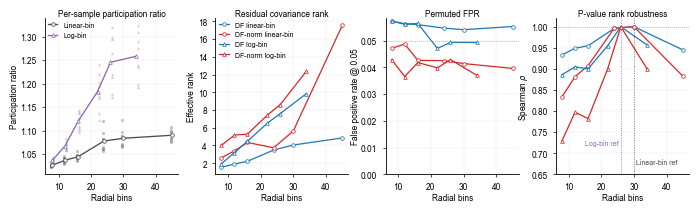

In [37]:
preview_subplot_panel(plot_radial_bin_diagnostics_row, figsize=(7, 2))

#### Save the combined figure

In [38]:
def build_ad_supp_hp_figure():
    """Assemble the high-pass/radial-bin AD/PIG supplement."""
    fig = plt.figure(figsize=(185 / 25.4, 190 / 25.4))
    outer = gridspec.GridSpec(
        4, 1,
        figure=fig,
        left=0.05,
        right=0.95,
        top=0.95,
        bottom=0.05,
        hspace=0.5,
        height_ratios=[0.8, 1.2, 1.2, 1.2],
    )
    plot_binning_profile_comparison(outer[0])
    plot_null_ecdf_comparison_row(outer[1])
    plot_positive_control_sensitivity_row(outer[2])
    plot_radial_bin_diagnostics_row(outer[3])
    return fig

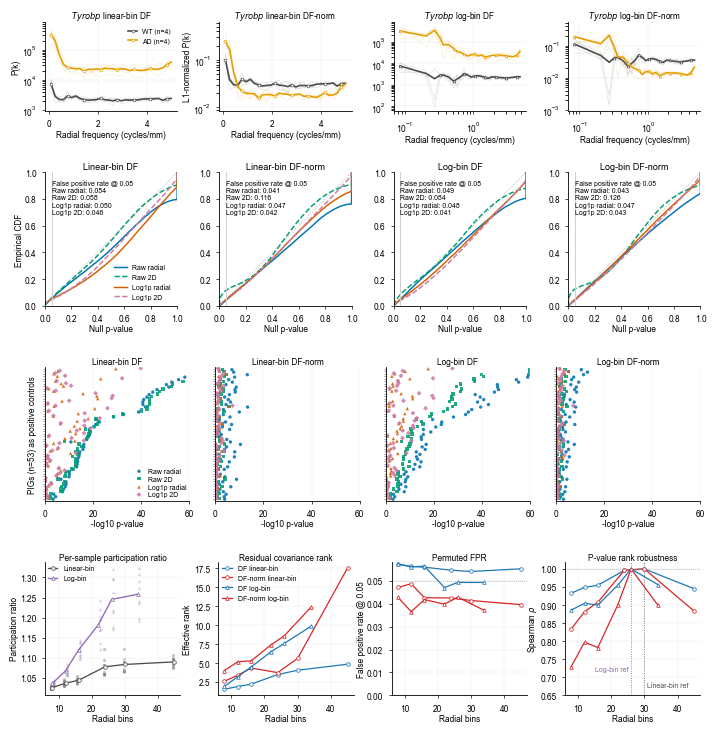

In [39]:
fig = build_ad_supp_hp_figure()
plt.show()

In [40]:
fig = build_ad_supp_hp_figure()
fig.savefig(FIGURE_DIR / "ad_supp_hp.pdf", bbox_inches=None)
plt.close(fig)

### Additional sanity checks

#### Anisotropy distribution

Most genes have near-zero anisotropy values, so we use radial feature mode for the test.

In [41]:
def _center_crop_power(power, shape):
    ny, nx = power.shape
    ty, tx = shape
    y0 = max((ny - ty) // 2, 0)
    x0 = max((nx - tx) // 2, 0)
    return power[y0:y0 + ty, x0:x0 + tx]


def _mean_fft_display_power(gene, sample_idx):
    gi = ad_genes.index(gene)
    parts = [_fft_display_data(ad_cmp, int(idx), gi)[0] for idx in sample_idx]
    min_shape = (min(p.shape[0] for p in parts), min(p.shape[1] for p in parts))
    cropped = [_center_crop_power(np.asarray(p, dtype=float), min_shape) for p in parts]
    return np.nanmean(np.stack(cropped, axis=0), axis=0)


def _display_anisotropy_axis(power):
    power = np.maximum(np.asarray(power, dtype=float), 0.0)
    ny, nx = power.shape
    yy, xx = np.indices(power.shape)
    cx = (nx - 1) / 2.0
    cy = (ny - 1) / 2.0
    dx = xx - cx
    dy = yy - cy
    radius = np.sqrt(dx * dx + dy * dy)
    theta = np.arctan2(dy, dx)
    mask = radius > 1.0
    weights = power[mask]
    total = float(weights.sum())
    if total <= 0:
        return np.nan, 0.0
    cos2 = float((weights * np.cos(2.0 * theta[mask])).sum())
    sin2 = float((weights * np.sin(2.0 * theta[mask])).sum())
    score = math.sqrt(cos2 * cos2 + sin2 * sin2) / total
    angle = 0.5 * math.atan2(sin2, cos2)
    return score, angle


def _draw_spectrum_axis(ax, power):
    _score, angle = _display_anisotropy_axis(power)
    ny, nx = power.shape
    cx = (nx - 1) / 2.0
    cy = (ny - 1) / 2.0
    length = 0.38 * min(nx, ny)
    dx = length * math.cos(angle)
    dy = length * math.sin(angle)
    ax.plot([cx - dx, cx + dx], [cy - dy, cy + dy], color="black", lw=1.75, alpha=0.35, zorder=3)
    ax.plot([cx - dx, cx + dx], [cy - dy, cy + dy], color="white", lw=1.05, alpha=0.95, zorder=4)


def _wrap_angle_deg(values):
    return ((np.asarray(values, dtype=float) + 90.0) % 180.0) - 90.0


def _axis_aligned_fraction(angles, tol=7.5):
    angles = np.asarray(angles, dtype=float)
    distance = np.minimum(np.abs(angles), np.abs(np.abs(angles) - 90.0))
    return float(np.nanmean(distance <= tol))


def _top_anisotropy_gene(pig_long):
    wide = pig_long.pivot_table(index="gene", columns="group", values="anisotropy", aggfunc="mean")
    if not {"WT", "AppNL-G-F"}.issubset(wide.columns):
        return None, wide
    wide["delta"] = wide["AppNL-G-F"] - wide["WT"]
    return str(wide["delta"].idxmax()), wide


def _plot_anisotropy_spectrum_example(container, pig_long):
    """Show the anisotropy spectra for the top anisotropy gene."""
    gene, wide = _top_anisotropy_gene(pig_long)
    if gene is None:
        container.axis("off")
        return
    wt_power = _mean_fft_display_power(gene, ad_wt_idx)
    tg_power = _mean_fft_display_power(gene, ad_tg_idx)
    log_panels = [np.log10(np.maximum(wt_power, 1e-12)), np.log10(np.maximum(tg_power, 1e-12))]
    finite = np.concatenate([p[np.isfinite(p)] for p in log_panels])
    vmin, vmax = np.nanpercentile(finite, [3, 99.5])

    container.axis("off")
    container.set_title(f"Example raw 2D spectra ($\\it{{{gene}}}$)", fontsize=6, pad=2)

    panel_specs = [
        (0.00, 0.13, 0.48, 0.72, wt_power, "WT", GROUP_COLORS["WT"], wide.loc[gene, "WT"]),
        (0.5, 0.13, 0.48, 0.72, tg_power, "AppNL-G-F", GROUP_COLORS["AD"], wide.loc[gene, "AppNL-G-F"]),
    ]
    for x0, y0, w, h, power, label, color, score in panel_specs:
        ax = container.inset_axes([x0, y0, w, h])
        ax.imshow(
            np.log10(np.maximum(power, 1e-12)),
            origin="lower",
            cmap="magma",
            vmin=vmin,
            vmax=vmax,
            interpolation="nearest",
            rasterized=True,
        )
        _draw_spectrum_axis(ax, power)
        ax.set_title(f"{label}\nA={score:.3f}", fontsize=5, color=color, pad=2.0)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)


def _plot_gene_set_boxplots_by_sample(
    ax,
    long,
    sample_order,
    *,
    value_col,
    title,
    ylabel,
    angle=False,
    show_legend=False,
):
    """Plot boxplots per sample for the selected value column."""
    plot_df = long.copy()
    if angle:
        plot_df["plot_value"] = _wrap_angle_deg(plot_df[value_col])
        for ref, ls, lw in ((-90, ":", 0.5), (0, "--", 0.5), (90, ":", 0.5)):
            ax.axhline(ref, color="0.7", lw=lw, ls=ls, zorder=0)
    else:
        plot_df["plot_value"] = pd.to_numeric(plot_df[value_col], errors="coerce")

    n_bg = int(plot_df.loc[plot_df["gene_set"] == "non-PIG", "gene"].nunique())
    n_pig = int(plot_df.loc[plot_df["gene_set"] == "PIG", "gene"].nunique())
    group_by_sample = (
        plot_df[["sample", "group"]]
        .drop_duplicates()
        .set_index("sample")["group"]
        .to_dict()
    )
    positions = []
    data = []
    styles = []
    for i, sample in enumerate(sample_order):
        group = group_by_sample.get(sample, "")
        pig_color = GROUP_COLORS["WT"] if group == "WT" else GROUP_COLORS["AD"]
        for gene_set, offset, face, edge in (
            ("non-PIG", -0.2, "0.86", "0.50"),
            ("PIG", 0.2, pig_color, "0.20"),
        ):
            vals = (
                plot_df.loc[(plot_df["sample"] == sample) & (plot_df["gene_set"] == gene_set), "plot_value"]
                .dropna()
                .to_numpy(float)
            )
            if vals.size == 0:
                continue
            positions.append(i + offset) # per-group offset adjustment
            data.append(vals)
            styles.append((gene_set, group, face, edge))

    bp = ax.boxplot(
        data,
        positions=positions,
        widths=0.3,
        patch_artist=True,
        showfliers=False,
        whis=(5, 95),
        manage_ticks=False,
        medianprops={"color": "0.10", "linewidth": 0.5},
        whiskerprops={"color": "0.5", "linewidth": 0.5},
        capprops={"color": "0.5", "linewidth": 0.5},
    )
    for patch, (gene_set, group, face, edge) in zip(bp["boxes"], styles, strict=True):
        patch.set_facecolor(face)
        patch.set_edgecolor(edge)
        patch.set_linewidth(0.5)
        patch.set_alpha(0.78 if gene_set == "PIG" else 0.92)

    ax.set_xticks(range(len(sample_order)))
    ax.set_xticklabels(sample_order, rotation=35, ha="right", fontsize=5)
    ax.set_ylabel(ylabel, labelpad=1)
    ax.set_title(title, fontsize=6, pad=2)
    ax.grid(axis="y", color="0.90", lw=0.35, alpha=0.75)
    if angle:
        ax.set_ylim(-94, 94)
        ax.set_yticks([-90, -45, 0, 45, 90])

    handles = [
        mpl.patches.Patch(facecolor="0.86", edgecolor="0.50", label=f"non-PIG (n={n_bg})", alpha=0.92),
        mpl.patches.Patch(facecolor=GROUP_COLORS["WT"], edgecolor="0.20", label=f"WT PIG (n={n_pig})", alpha=0.78),
        mpl.patches.Patch(facecolor=GROUP_COLORS["AD"], edgecolor="0.20", label=f"AppNL-G-F PIG (n={n_pig})", alpha=0.78),
    ]
    if show_legend:
        ax.legend(handles=handles, frameon=False, fontsize=5, loc="upper left", handlelength=1.1, handletextpad=0.35)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


def plot_ad_pig_anisotropy_row(axspec):
    """Draw PIG/non-PIG anisotropy summaries and an example spectrum."""
    fig = plt.gcf()
    gs = gridspec.GridSpecFromSubplotSpec(
        1, 3, 
        subplot_spec=axspec, 
        wspace=0.3, 
        width_ratios=[1, 1, 1]
    )

    # Load precomputed data
    long = AD_PIG_ANISOTROPY.copy()
    pig_long = long[long["gene_set"] == "PIG"].copy()
    group_order = {"WT": 0, "AppNL-G-F": 1}
    sample_order = (
        long[["sample", "group"]]
        .drop_duplicates()
        .assign(group_order=lambda d: d["group"].map(group_order).fillna(9))
        .sort_values(["group_order", "sample"])["sample"]
        .tolist()
    )

    # Plot the per-sample anisotropy distribution
    ax = fig.add_subplot(gs[0, 0])
    _plot_gene_set_boxplots_by_sample(
        ax,
        long,
        sample_order,
        value_col="anisotropy",
        title="Raw 2D anisotropy by sample",
        ylabel="Raw 2D anisotropy",
        show_legend=True,
    )

    # Plot the per-sample dominant angle distribution
    ax = fig.add_subplot(gs[0, 1])
    _plot_gene_set_boxplots_by_sample(
        ax,
        long,
        sample_order,
        value_col="dominant_angle_deg",
        title="Raw 2D dominant angle by sample",
        ylabel="Dominant angle (deg)",
        angle=True,
        show_legend=False,
    )

    # Plot the anisotropy spectrum for an example gene
    ax = fig.add_subplot(gs[0, 2])
    _plot_anisotropy_spectrum_example(ax, pig_long)

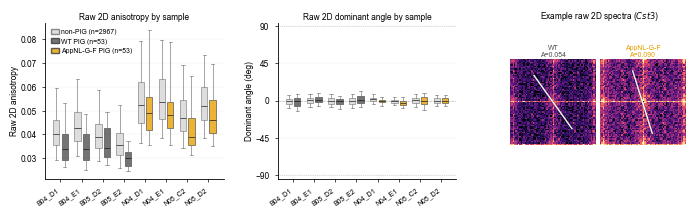

In [42]:
preview_subplot_panel(plot_ad_pig_anisotropy_row, figsize=(7, 2))

#### Within- vs between-animal variance per frequency bin

The mouse AD dataset contains 8 spatial slides from 4 different animals. Here we analyze the pairwise relative distance in frequency radial powers between two slides (1) within the same animal and (2) between different animals. Shown below are the per-gene distributions of these distances, grouped by disease condition and averaged across pairs.

In [43]:
# Load precomputed data
def _replicate_distance_plot_data():
    """Load and process replicate distance data for plotting."""
    long = AD_PIG_REPLICATE_DISTANCE.copy()
    long = long[long["panel"].eq("ad_pig")].copy()
    long["bin_index"] = pd.to_numeric(long["bin_index"], errors="coerce").astype(int)
    long["relative_distance"] = pd.to_numeric(long["relative_distance"], errors="coerce")
    long = long[np.isfinite(long["relative_distance"])].copy()
    # Plot distributions across genes after averaging over available section-pair
    # comparisons for each condition / within-vs-cross relation / bin.
    return (
        long.groupby(["condition", "relation", "bin", "bin_index", "bin_type", "gene"], as_index=False)
        .agg(mean_relative_distance=("relative_distance", "mean"))
        .sort_values(["condition", "relation", "bin_index", "gene"], kind="stable")
    )

AD_PIG_REPLICATE_DISTANCE_PLOT = _replicate_distance_plot_data()


def plot_replicate_distance_condition(ax, condition, *, show_xlabel=False, show_legend=False):
    """Plot the replicate distance for a given condition."""
    df = AD_PIG_REPLICATE_DISTANCE_PLOT[AD_PIG_REPLICATE_DISTANCE_PLOT["condition"].eq(condition)].copy()
    relation_order = ["within_animal", "cross_animal"]
    relation_labels = {"within_animal": "Within animal", "cross_animal": "Cross animal"}
    relation_colors = {"within_animal": "#4c78a8", "cross_animal": "#e45756"}
    bins = np.arange(int(df["bin_index"].min()), int(df["bin_index"].max()) + 1)
    width = 0.3
    offsets = {"within_animal": -0.2, "cross_animal": 0.2}
    for relation in relation_order:
        data = [
            df.loc[
                df["relation"].eq(relation) & df["bin_index"].eq(bin_i),
                "mean_relative_distance",
            ].to_numpy(float)
            for bin_i in bins
        ]
        bp = ax.boxplot(
            data,
            positions=bins + offsets[relation], # per-group offset
            widths=width,
            patch_artist=True,
            showfliers=False,
            whis=(5, 95),
            manage_ticks=False,
            medianprops={"color": "0.10", "linewidth": 0.5},
            whiskerprops={"color": "0.5", "linewidth": 0.5},
            capprops={"color": "0.5", "linewidth": 0.5},
        )
        for box in bp["boxes"]:
            box.set_facecolor(relation_colors[relation])
            box.set_alpha(0.68)

    # Use discrete labels and tick positions
    labels = ["DC", "1", "5", "10", "15", "20", "25", "30"]
    tick_pos = [0, 1, 5, 10, 15, 20, 25, 30]
    tick_pos = [x for x in tick_pos if x in set(bins)]
    ax.set_xticks(tick_pos)
    ax.set_xticklabels([labels[[0, 1, 5, 10, 15, 20, 25, 30].index(x)] for x in tick_pos])
    ax.set_xlim(-0.7, bins.max() + 0.7)

    if show_xlabel:
        ax.set_xlabel("DC and non-DC radial frequency bin")
    else:
        ax.set_xticklabels([])
    ax.set_ylabel("Mean relative distance")
    ax.set_title(f"Per-gene pairwise relative distance in bin power ({condition})", fontsize=7, pad=2)
    ax.grid(axis="y", color="0.90", linewidth=0.45)

    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    if show_legend:
        handles = [
            mpatches.Patch(
                facecolor=relation_colors[rel],
                edgecolor="0.25",
                alpha=0.68,
                label=relation_labels[rel],
            )
            for rel in relation_order
        ]
        ax.legend(handles=handles, loc="upper right", frameon=False, ncol=2, handlelength=1.0)


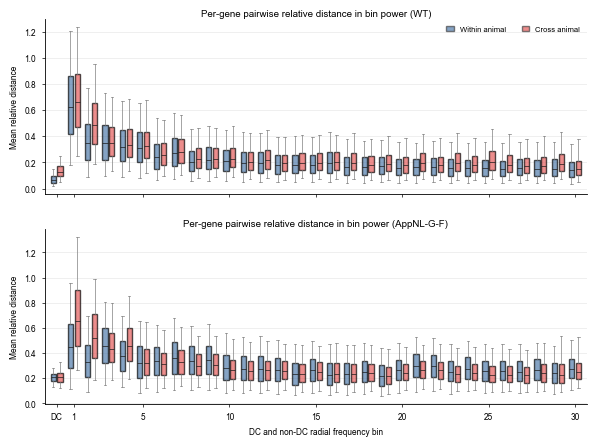

In [44]:
fig, axes = plt.subplots(2, 1, figsize=(7, 5))
for i, condition in enumerate(["WT", "AppNL-G-F"]):
    plot_replicate_distance_condition(
        axes[i],
        condition,
        show_xlabel=(i == 1),
        show_legend=(i == 0),
    )

#### Save the combined figure

In [45]:
def build_ad_supp_replicates_figure():
    """Assemble anisotropy and technical-replicate spectral-distance panels."""
    fig = plt.figure(figsize=(185 / 25.4, 150 / 25.4))
    gs = gridspec.GridSpec(
        4, 1,
        figure=fig,
        left=0.05,
        right=0.95,
        top=0.95,
        bottom=0.05,
        hspace=0.4,
        height_ratios=[1.0, 0.02, 1.0, 1.0],
    )
    plot_ad_pig_anisotropy_row(gs[0])
    # gs[1] is for the spacing between the anisotropy and replicate distance plots
    for i, condition in enumerate(["WT", "AppNL-G-F"]):
        ax = fig.add_subplot(gs[i + 2, 0])
        plot_replicate_distance_condition(
            ax,
            condition,
            show_xlabel=(i == 1),
            show_legend=(i == 0),
        )
    return fig

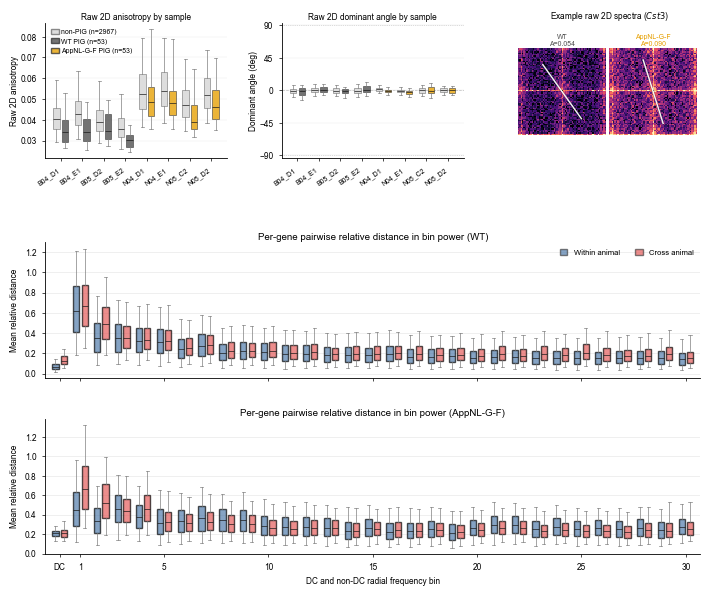

In [46]:
fig = build_ad_supp_replicates_figure()
plt.show()

In [47]:
fig = build_ad_supp_replicates_figure()
fig.savefig(FIGURE_DIR / "ad_supp_sanity.pdf", bbox_inches=None)
plt.close(fig)